# Braking that travels: do Combine cuts predict rookie receiver separation?

**OBSERVED RESEARCH ACCOUNT — OCTOBER 13, 2026.** The official files have been downloaded and the retained primary experiment and diagnostics have run. The original single-drill model failed. The expanded model improves the observed score against the original baseline, while its incremental motion value remains uncertain. This notebook reproduces the analysis from the official input. It has not been publicly published or submitted.

A coach sees a receiver arrive at a break, reduce speed, change direction, and escape. The forty-yard time summarizes straight-line speed; it does not describe that tradeoff. We ask whether a shared Combine route drill supplies useful information about rookie separation after accounting for conventional tests and game situations.

The official description reports 510 prospects from 2023–2025, 6,310 Combine attempts, and 316,338 player-play rows. Downloaded bytes confirm 510 prospects and 6,310 Combine attempts, but player-play records total 314,197 rather than 316,338. The analysis joins official player identifiers, retains WR rookie regular seasons and non-nullified cutting routes, and requires at least twenty measured routes per player. The shared drill is selected by Combine availability before NFL outcomes. We report opt-outs and rejected attempts; target-only measurement would narrow the claim to targeted routes.

The primary features describe entry speed, retained speed at the break, exit gain, integrated braking, turn angle, curvature energy, jerk, and signed trajectory area. The area is the antisymmetric second-level path signature. Field coordinates are normalized by translation, entry direction, and turn handedness. Tracking is sampled at 10 Hz, so derivative noise and smoothing sensitivity matter.

The conventional comparison includes body measurements, the forty and ten-yard split, jumps, three-cone and shuttle, plus route, cushion, formation, coverage, down and field context. A scouting reference adds college production. Matched random forests test whether motion gains survive a nonlinear conventional model; physical and coverage interactions are exploratory. Career totals and draft position are excluded.

Training is restricted to the 2023 class in its rookie season, tuning to the 2024 class in its rookie season, and testing to the 2025 class in its rookie season. Imputation, encoding and scaling are fitted on development data. All attempts and routes belonging to a player stay in one cohort. Each player receives equal total fitting weight and equal total evaluation weight.

Our primary estimate is the reduction in player-balanced mean squared error from adding movement to a regularized linear baseline. A paired player bootstrap supplies uncertainty. A positive point estimate with an interval crossing zero is inconclusive. Results from one draft class cannot establish universal transport or a causal coaching intervention. We retain negative results and do not replace the primary contrast with a better-looking exploratory model after seeing test results.

The provided separation metric is essential: game trajectories cover the rookie cohort, so the notebook does not invent missing defender paths. Secondary game-cut measurements are descriptive outcome-side checks. They never enter the pre-draft predictor.

**Observed results:** the shared availability-selected drill is DAGGER_ROUTE_LEFT. The final cohort comprises 26 training, 21 validation and 17 test receivers, with 3,326, 2,285 and 1,737 routes. Conventional linear RMSE is 1.738 yards; motion-augmented RMSE is 1.823 yards. The baseline-minus-motion MSE difference is −0.302 squared yards, with paired-player 95% interval [−0.616, −0.078]. The augmentation is worse on this held-out task. Conventional forest RMSE is 1.721 versus 1.725 with motion; its difference interval crosses zero. Five- and nine-frame smoothing also underperform. Thirty development-player block shuffles are diagnostic only, not a p-value. Across 2,538 qualifying game cuts, the tested receiver-median mechanics correlations are weak (absolute Spearman rho at most 0.110). There is no supported predictive gain. The visual explanation is designed for coaches and fans: path shape and speed, the brake-turn-recovery curve, and a speed/acceleration portrait. Actual plots below are generated only after official data are attached.

**Data use:** noncommercial research only. Do not redistribute raw tracking or per-player private result files. Public competition code must also be posted on Kaggle as required by the rules. This file has not been published or submitted. Before outcome filtering, 15.1% of non-targeted routes lack separation, versus none of the targeted routes. This coverage bias and a single small test class limit generalization. All post-primary diagnostics are explicitly labeled as reusing the test cohort. This account stays within 2,000 words and six composite figures. References: [official data](https://www.kaggle.com/competitions/nfl-big-data-bowl-2027/data), [rules](https://www.kaggle.com/competitions/nfl-big-data-bowl-2027/rules).


In [1]:
import sys, platform, json
from pathlib import Path
import numpy, pandas, scipy, sklearn, matplotlib
print({"python": platform.python_version(), "numpy": numpy.__version__, "pandas": pandas.__version__, "scipy": scipy.__version__, "sklearn": sklearn.__version__, "matplotlib": matplotlib.__version__})


{'python': '3.12.14', 'numpy': '2.3.5', 'pandas': '2.2.3', 'scipy': '1.17.0', 'sklearn': '1.8.0', 'matplotlib': '3.10.8'}


## Reproducible implementation
This appendix contains all analysis code, rather than depending on a moving upstream repository. Random seed, feature definitions, cohort filters, models and bootstrap are fixed.

In [2]:
import types
A = types.ModuleType("bdb_analysis")
exec(compile('"""Combine-to-game research. No competition data are bundled or fabricated."""\nfrom pathlib import Path\nimport json, hashlib, argparse, platform\nimport numpy as np\nimport pandas as pd\nfrom scipy.signal import savgol_filter\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.preprocessing import OneHotEncoder, StandardScaler\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.linear_model import Ridge\nfrom sklearn.ensemble import RandomForestRegressor\n\nSEED=20271006\nBASE=[\'combine_height\',\'combine_weight\',\'ten_yd_split\',\'forty\',\'vertical\',\'broad_jump\',\'three_cone\',\'short_shuttle\']\nCONTEXT=[\'cushion\',\'down\',\'yards_to_go\',\'yardline_number\',\'pre_snap_home_score\',\'pre_snap_visitor_score\']\nCATS=[\'route_ran\',\'team_coverage_man_zone\',\'offense_formation\',\'in_motion_at_ball_snap\']\nMOTION=[\'entry_speed\',\'speed_retention\',\'exit_gain\',\'braking_impulse\',\'turn_angle\',\'curvature_energy\',\'jerk_rms\',\'signature_area\']\nCUT_ROUTES={\'OUT\',\'SLANT\',\'POST\',\'CORNER\',\'HITCH\'}\n\ndef movement(g,window=7):\n    """Largest interior heading change; fixed +/-0.5s event window, yards/seconds."""\n    g=g.sort_values(\'time\').copy()\n    t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9\n    if len(t)<21 or np.any(np.diff(t)<=0): raise ValueError(\'short or duplicate/nonmonotone trajectory\')\n    dt=np.diff(t)\n    if not np.allclose(dt,.1,atol=.015): raise ValueError(\'irregular sampling; do not interpolate missing cuts\')\n    p=g[[\'x\',\'y\']].to_numpy(float)\n    if not np.isfinite(p).all(): raise ValueError(\'nonfinite coordinates\')\n    p=savgol_filter(p,window,3,axis=0)\n    v=np.gradient(p,.1,axis=0);a=np.gradient(v,.1,axis=0)\n    speed=np.linalg.norm(v,axis=1)\n    theta=np.unwrap(np.arctan2(v[:,1],v[:,0]))\n    k=np.arange(5,len(p)-5)\n    score=np.abs(theta[k+3]-theta[k-3]);score[(speed[k-3]<1)|(speed[k+3]<1)]=0\n    if score.max()<np.deg2rad(25): raise ValueError(\'no qualifying turn\')\n    c=int(k[np.flatnonzero(np.isclose(score,score.max(),rtol=0,atol=1e-10))[0]]);sl=slice(c-5,c+6)\n    turn=theta[c+3]-theta[c-3]\n    tangent=v[c-3]/speed[c-3];normal=np.array([-tangent[1],tangent[0]])\n    q=(p[sl]-p[c-5])@np.stack([tangent,normal],axis=1)\n    q[:,1]*=1 if turn>=0 else -1\n    # Antisymmetric level-two path signature, equal to signed area with closing chord.\n    area=.5*np.sum(q[:-1,0]*q[1:,1]-q[:-1,1]*q[1:,0])\n    sp=speed[sl];at=np.gradient(sp,.1)\n    omega=np.gradient(theta,.1)[sl];curv=omega/np.maximum(sp,1)\n    out=dict(entry_speed=float(np.mean(sp[:3])),speed_retention=float(sp.min()/np.mean(sp[:3])),\n      exit_gain=float(np.mean(sp[-3:])-sp.min()),braking_impulse=float(np.trapezoid(np.maximum(-at,0),dx=.1)),\n      turn_angle=float(abs(turn)),curvature_energy=float(np.trapezoid(curv**2*sp,dx=.1)),\n      jerk_rms=float(np.sqrt(np.mean(np.gradient(a[sl],.1,axis=0)**2))),signature_area=float(area))\n    diag={\'t\':np.arange(-5,6)*.1,\'q\':q,\'speed\':sp,\'tangential_acceleration\':at,\'cut_index\':c}\n    return out,diag\n\ndef inventory(root):\n    """Stream all CSVs; retain observed counts/schema/hash, never treat descriptions as measured counts."""\n    rows=[]\n    for p in sorted(Path(root).glob(\'*.csv\')):\n        count=0;ids=set();years=set();cols=None\n        for c in pd.read_csv(p,chunksize=200000):\n            count+=len(c);cols=list(c.columns)\n            if \'nfl_id\' in c: ids.update(c.nfl_id.dropna().astype(int))\n            for key in (\'season\',\'draft_year\'):\n                if key in c:years.update(c[key].dropna().astype(int))\n        h=hashlib.sha256()\n        with p.open(\'rb\') as f:\n            for b in iter(lambda:f.read(8*1024*1024),b\'\'): h.update(b)\n        rows.append(dict(file=p.name,rows=count,unique_players=len(ids),years=sorted(years),columns=cols,sha256=h.hexdigest()))\n    return rows\n\ndef prepare(root,out):\n    root,out=Path(root),Path(out);out.mkdir(parents=True,exist_ok=True)\n    players=pd.read_csv(root/\'players.csv\');combine=pd.read_csv(root/\'combine_results.csv\');games=pd.read_csv(root/\'games.csv\')\n    for d,key in [(players,[\'nfl_id\']),(combine,[\'nfl_id\',\'draft_year\']),(games,[\'game_id\'])]:\n        if d.duplicated(key).any():raise ValueError(\'duplicate metadata join key\')\n    ids=set(players.loc[players.nfl_position.eq(\'WR\'),\'nfl_id\']);pieces=[]\n    drill_counts={}\n    for c in pd.read_csv(root/\'combine_tracking.csv\',chunksize=200000):\n        c=c[c.nfl_id.isin(ids)&c.entity_type.eq(\'PLAYER\')&c.drill_type.eq(\'SKILL_DRILLS_WR\')]\n        pieces.append(c)\n        for name,n in c.drill_name.value_counts().items():drill_counts[name]=drill_counts.get(name,0)+int(n)\n    track=pd.concat(pieces,ignore_index=True);features=[];rejects=[]\n    for keys,g in track.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        try:\n            f,_=movement(g);features.append(dict(nfl_id=keys[0],draft_year=keys[1],event_id=keys[2],drill_name=g.drill_name.iloc[0],**f))\n        except ValueError as e:rejects.append(dict(event_id=keys[2],reason=str(e)))\n    f=pd.DataFrame(features)\n    if f.empty:raise ValueError(\'no qualifying WR turns; inspect drill availability before changing protocol\')\n    f.to_csv(out/\'attempt_features.csv\',index=False)\n    # Choose one homologous drill using Combine availability only, before NFL outcomes.\n    availability=f.groupby([\'drill_name\',\'draft_year\']).nfl_id.nunique().unstack(fill_value=0).reindex(columns=[2023,2024,2025],fill_value=0)\n    minimum=availability.min(axis=1);eligible=minimum[minimum>=5]\n    if eligible.empty:raise ValueError(\'no qualifying drill shared by >=5 WRs in every class; inspect availability\')\n    selected=sorted(eligible.index,key=lambda k:(-eligible[k],k))[0]\n    f=f[f.drill_name.eq(selected)]\n    agg=f.groupby([\'nfl_id\',\'draft_year\'])[MOTION].median().reset_index()\n    pp=pd.read_csv(root/\'player_play.csv\')\n    if pp.duplicated([\'game_id\',\'play_id\',\'nfl_id\']).any():raise ValueError(\'duplicate player-play key\')\n    pp=pp.merge(games[[\'game_id\',\'season\',\'season_type\']],on=\'game_id\',validate=\'many_to_one\').merge(players[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\')\n    d=pp[pp.nfl_position.eq(\'WR\')&pp.season.eq(pp.draft_year)&pp.season_type.eq(\'REG\')&pp.route_ran.isin(CUT_ROUTES)&pp.play_nullified_by_penalty.eq(\'N\')].copy()\n    d=d[np.isfinite(d.separation_at_pass_forward)&(d.separation_at_pass_forward>=0)]\n    d=d.merge(combine,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\').merge(agg,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\')\n    # Each player must have >=20 measured routes. Threshold is frozen before labels are inspected.\n    n=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(n[n>=20].index)]\n    audit={\'status\':\'actual_data_prepared\',\'draft_class_players\':d.groupby(\'draft_year\').nfl_id.nunique().to_dict(),\n      \'draft_class_routes\':d.groupby(\'draft_year\').size().to_dict(),\'wr_roster_players\':len(ids),\'qualifying_attempts\':len(f),\n      \'selected_drill\':selected,\'drill_player_availability\':availability.to_dict(),\'excluded_attempts\':rejects,\'drill_frame_counts\':drill_counts,\'target_only_fraction\':float(d.target.mean()) if len(d) else None,\n      \'game_tracking_use\':\'Primary outcome uses official separation; game trajectory replication remains secondary and unrun.\'}\n    temp=out/\'private_analysis_rows.csv.tmp\';d.to_csv(temp,index=False);temp.replace(out/\'private_analysis_rows.csv\');\n    if len(pd.read_csv(out/\'private_analysis_rows.csv\'))!=len(d):raise ValueError(\'analysis CSV roundtrip row mismatch\')\n    d.to_pickle(out/\'private_analysis_rows.pkl\');(out/\'population_audit.json\').write_text(json.dumps(audit,indent=2))\n    return d,f,audit\n\ndef model(d,nums,kind,alpha=10):\n    numeric=Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())])\n    cats=Pipeline([(\'impute\',SimpleImputer(strategy=\'most_frequent\')),(\'onehot\',OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False))])\n    pre=ColumnTransformer([(\'numeric\',numeric,nums),(\'category\',cats,CATS)])\n    reg=Ridge(alpha=alpha) if kind==\'ridge\' else RandomForestRegressor(n_estimators=200,min_samples_leaf=20,max_depth=6,max_features=.8,random_state=SEED,n_jobs=2)\n    return Pipeline([(\'pre\',pre),(\'reg\',reg)])\n\ndef weights(d):return 1/d.groupby(\'nfl_id\').nfl_id.transform(\'size\').to_numpy()\ndef score(d,p):return float(np.average((d.separation_at_pass_forward.to_numpy()-p)**2,weights=weights(d)))\n\ndef compare(d,out):\n    """Player-disjoint, rookie-season-disjoint validation and locked 2025 test."""\n    out=Path(out);out.mkdir(parents=True,exist_ok=True);d=d.copy()\n    if not (d.season==d.draft_year).all():raise ValueError(\'rookie seasons required\')\n    for col in MOTION:\n        d[col+\'_mass\']=d[col]*d.combine_weight/200\n        d[col+\'_man\']=d[col]*d.team_coverage_man_zone.eq(\'MAN_COVERAGE\').astype(int)\n    families={\'conventional\':BASE+CONTEXT,\'tracking\':BASE+CONTEXT+MOTION,\n      \'physical_context_interactions\':BASE+CONTEXT+MOTION+[c+s for c in MOTION for s in (\'_mass\',\'_man\')],\n      \'scouting_reference\':BASE+CONTEXT+[\'ngs_college_production_score\']}\n    a,b,t=[d[d.draft_year.eq(y)] for y in (2023,2024,2025)]\n    if min(x.nfl_id.nunique() for x in (a,b,t))<10:raise ValueError(\'fewer than ten WRs in a class; insufficient locked-cohort study\')\n    assert not(set(a.nfl_id)&set(b.nfl_id) or set(a.nfl_id)&set(t.nfl_id) or set(b.nfl_id)&set(t.nfl_id))\n    dev=pd.concat([a,b]);results=[];pred={};selections={}\n    for kind in (\'ridge\',\'forest\'):\n      for family,nums in families.items():\n        options=(1,10,100) if kind==\'ridge\' else (10,)\n        vals=[]\n        for alpha in options:\n            m=model(a,nums,kind,alpha);m.fit(a,a.separation_at_pass_forward,reg__sample_weight=weights(a));vals.append((score(b,m.predict(b)),alpha))\n        _,alpha=min(vals);selections[kind+\'_\'+family]={\'alpha\':alpha,\'validation_mse\':min(vals)[0]}\n        m=model(dev,nums,kind,alpha);m.fit(dev,dev.separation_at_pass_forward,reg__sample_weight=weights(dev));p=m.predict(t)\n        name=kind+\'_\'+family;pred[name]=p\n        results.append({\'model\':name,\'test_player_balanced_mse\':score(t,p),\'test_rmse_yards\':score(t,p)**.5,\'validation_mse\':min(vals)[0]})\n    # Primary contrast is ridge tracking vs ridge conventional. Others exploratory.\n    losses=pd.DataFrame({\'nfl_id\':t.nfl_id,\'baseline\':(t.separation_at_pass_forward-pred[\'ridge_conventional\'])**2,\'tracking\':(t.separation_at_pass_forward-pred[\'ridge_tracking\'])**2}).groupby(\'nfl_id\').mean()\n    delta=(losses.baseline-losses.tracking).to_numpy();rng=np.random.default_rng(SEED)\n    boots=np.mean(rng.choice(delta,(5000,len(delta)),replace=True),axis=1)\n    report={\'status\':\'actual_data_completed\',\'primary_delta_mse_yards_squared\':float(delta.mean()),\'player_bootstrap_ci95\':np.quantile(boots,[.025,.975]).tolist(),\n      \'test_players\':len(delta),\'test_routes\':len(t),\'results\':results,\'selection\':selections,\n      \'interpretation\':\'positive delta favors motion; CI crossing zero is inconclusive; cohort-generalization requires more years\',\n      \'selection_warning\':\'Exploratory models cannot replace the preregistered primary contrast after observing test labels.\'}\n    pd.DataFrame(results).to_csv(out/\'model_comparisons.csv\',index=False)\n    (out/\'experiment_results.json\').write_text(json.dumps(report,indent=2))\n    pp=t[[\'nfl_id\',\'game_id\',\'play_id\']].copy()\n    for k,v in pred.items():pp[k]=v\n    pp.to_csv(out/\'private_test_predictions.csv\',index=False)\n    return report\n\ndef plot_motion(diag,path,label):\n    import matplotlib;matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    plt.rcParams.update({\'font.family\':\'DejaVu Sans\',\'text.color\':\'#e6edf6\',\'axes.labelcolor\':\'#c2cfde\',\'xtick.color\':\'#8aa0b6\',\'ytick.color\':\'#8aa0b6\',\'axes.edgecolor\':\'#304359\',\'axes.facecolor\':\'#102236\',\'figure.facecolor\':\'#071421\'})\n    fig,ax=plt.subplots(1,3,figsize=(16,5),layout=\'constrained\');q=diag[\'q\'];t=diag[\'t\'];s=diag[\'speed\'];a=diag[\'tangential_acceleration\']\n    sc=ax[0].scatter(q[:,0],q[:,1],c=s,cmap=\'plasma\',s=80,zorder=3);ax[0].plot(q[:,0],q[:,1],color=\'#39dbbd\',alpha=.8);ax[0].set_aspect(\'equal\');ax[0].set(xlabel=\'Along entry direction · yards\',ylabel=\'Across entry direction · yards\',title=\'THE SHAPE OF THE CUT\');fig.colorbar(sc,ax=ax[0],label=\'Speed · yd/s\',shrink=.7)\n    ax[1].plot(t,s,lw=3,color=\'#39dbbd\');ax[1].axvline(0,color=\'#efb455\',ls=\':\');ax[1].set(xlabel=\'Seconds from largest turn\',ylabel=\'Speed · yd/s\',title=\'BRAKE → TURN → RECOVER\')\n    ax[2].plot(s,a,lw=2,color=\'#efb455\');ax[2].scatter(s,a,c=t,cmap=\'cool\',s=40);ax[2].axhline(0,color=\'#304359\');ax[2].set(xlabel=\'Speed · yd/s\',ylabel=\'Tangential acceleration · yd/s²\',title=\'MOVEMENT PHASE PORTRAIT\')\n    for z in ax:z.grid(alpha=.12)\n    fig.suptitle(label,fontsize=17,fontweight=\'bold\');fig.savefig(path,dpi=150);plt.close(fig)\n\ndef run(root,out):\n    out=Path(out);out.mkdir(parents=True,exist_ok=True)\n    (out/\'inventory.json\').write_text(json.dumps(inventory(root),indent=2))\n    d,f,audit=prepare(root,out);report=compare(d,out)\n    # Selected example by sorted ID, independent of outcomes. Read only WR tracking rows.\n    chosen=f.sort_values([\'nfl_id\',\'event_id\']).iloc[0];parts=[]\n    for c in pd.read_csv(Path(root)/\'combine_tracking.csv\',chunksize=200000):parts.append(c[c.event_id.eq(chosen.event_id)&c.entity_type.eq(\'PLAYER\')])\n    g=pd.concat(parts);_,diag=movement(g);plot_motion(diag,out/\'actual_combine_geometry.png\',\'Observed Combine trajectory · selected without NFL outcomes\')\n    (out/\'actual_combine_geometry.html\').write_text(motion_html(diag,\'Observed Combine attempt · selected independently of NFL outcomes\'))\n    return report\n\n\ndef game_transfer(root,d,out):\n    """Secondary descriptive mechanics replication; game motion never a prospect predictor."""\n    out=Path(out);pieces=[];ids=set(d.nfl_id)\n    keys=d[[\'game_id\',\'play_id\',\'nfl_id\']].drop_duplicates()\n    for year in (2023,2024,2025):\n        p=Path(root)/f\'game_tracking_{year}.csv\';parts=[]\n        for c in pd.read_csv(p,chunksize=200000):\n            c=c[c.nfl_id.isin(ids)].merge(keys,on=[\'game_id\',\'play_id\',\'nfl_id\'],how=\'inner\',validate=\'many_to_one\');parts.append(c)\n        frames=pd.concat(parts,ignore_index=True)\n        for key,g in frames.groupby([\'game_id\',\'play_id\',\'nfl_id\']):\n            g=g.sort_values(\'time\');snap=g[g.event.eq(\'ball_snap\')];release=g[g.event.eq(\'pass_forward\')]\n            if snap.empty or release.empty:continue\n            g=g[g.time.ge(snap.time.iloc[0])&g.time.le(release.time.iloc[0])]\n            try:\n                f,_=movement(g);pieces.append(dict(game_id=key[0],play_id=key[1],nfl_id=key[2],**f))\n            except ValueError:continue\n    pd.DataFrame(pieces).to_csv(out/\'private_game_motion.csv\',index=False)\n    return {\'status\':\'descriptive_only\',\'qualifying_game_turns\':len(pieces),\'note\':\'No 22-player coverage reconstruction. Game movement is outcome-side diagnostic, never a pre-draft predictor.\'}\n\ndef motion_html(diag,label):\n    """Offline SVG animation of measured samples, not a generated football replay."""\n    import html\n    data=json.dumps({k:diag[k].tolist() for k in (\'t\',\'q\',\'speed\',\'tangential_acceleration\')})\n    template=\'\'\'<!doctype html><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Inside the cut</title><style>\nbody{background:#071421;color:#e6edf6;font:17px system-ui;margin:0;padding:4vw}main{max-width:1000px;margin:auto}.tag{color:#39dbbd;font-size:12px;letter-spacing:2px}h1{font-size:clamp(28px,5vw,52px)}.layout{display:grid;grid-template-columns:2fr 1fr;gap:24px}svg{background:#102236;width:100%;border-radius:20px}button{background:#39dbbd;color:#071421;border:0;border-radius:9px;padding:12px 22px;font-weight:700}input{width:100%;accent-color:#39dbbd}small{color:#9cafc3}strong{font-size:40px;display:block}.metric{margin:22px 0}@media(max-width:650px){.layout{grid-template-columns:1fr}} </style>\n<main><div class="tag">MOVEMENT LAB · FRAME BY FRAME</div><h1>Inside the cut.</h1><p>LABEL</p><div class="layout"><svg id="field" viewBox="0 0 600 400" role="img" aria-label="Canonical trajectory in yards"><g id="grid"></g><path id="path" fill="none" stroke="#39dbbd" stroke-width="3"/><g id="samples"></g><circle id="player" r="12" fill="#efb455" stroke="#071421" stroke-width="4"/><text x="22" y="380" fill="#9cafc3" font-size="14">Canonical entry frame · yards</text></svg><aside><div class="metric">Time from detected turn<strong id="time"></strong><small>seconds</small></div><div class="metric">Speed<strong id="speed"></strong><small>yards / second</small></div><div class="metric">Braking / reacceleration<strong id="acc"></strong><small>yards / second²</small></div></aside></div><p><button id="play">Play movement</button> <small>Eleven observed samples; interpolation animates the marker only.</small></p><input id="frame" type="range" min="0" max="10" step=".01" value="0" aria-label="Inspect tracking moment"><p><small>The line is the sampled path. Color indicates speed. A positive acceleration value means the athlete is regaining speed. The dot does not represent a defender or a missing NFL player.</small></p></main>\n<script>const D=DATA;const ns=\'http://www.w3.org/2000/svg\';const xs=D.q.map(p=>p[0]),ys=D.q.map(p=>p[1]);let xmin=Math.min(...xs),xmax=Math.max(...xs),ymin=Math.min(...ys),ymax=Math.max(...ys);const scale=Math.min(500/Math.max(xmax-xmin,.2),280/Math.max(ymax-ymin,.2));const P=D.q.map(p=>[50+(p[0]-xmin)*scale,330-(p[1]-ymin)*scale]);function node(tag,attrs,parent){let e=document.createElementNS(ns,tag);for(let k in attrs)e.setAttribute(k,attrs[k]);parent.appendChild(e);return e}for(let x=Math.floor(xmin);x<=xmax;x++){const z=50+(x-xmin)*scale;node(\'line\',{x1:z,y1:20,x2:z,y2:350,stroke:\'#233c51\'},document.querySelector(\'#grid\'));const t=node(\'text\',{x:z,y:365,fill:\'#9cafc3\',\'font-size\':12},document.querySelector(\'#grid\'));t.textContent=x;}document.querySelector(\'#path\').setAttribute(\'d\',P.map((p,i)=>(i?\'L\':\'M\')+p.join(\',\')).join(\' \'));let low=Math.min(...D.speed),high=Math.max(...D.speed);P.forEach((p,i)=>node(\'circle\',{cx:p[0],cy:p[1],r:5,fill:`hsl(${180-140*(D.speed[i]-low)/Math.max(high-low,.01)} 75% 60%)`},document.querySelector(\'#samples\')));let f=document.querySelector(\'#frame\'),playing=false,last=0;function show(){let z=+f.value,i=Math.min(9,Math.floor(z)),a=z-i;let p=P[i].map((v,k)=>v+(P[i+1][k]-v)*a);document.querySelector(\'#player\').setAttribute(\'cx\',p[0]);document.querySelector(\'#player\').setAttribute(\'cy\',p[1]);for(let [id,key] of [[\'time\',\'t\'],[\'speed\',\'speed\'],[\'acc\',\'tangential_acceleration\']])document.querySelector(\'#\'+id).textContent=(D[key][i]+(D[key][i+1]-D[key][i])*a).toFixed(2)}f.oninput=()=>{playing=false;document.querySelector(\'#play\').textContent=\'Play movement\';show()};document.querySelector(\'#play\').onclick=()=>{playing=!playing;if(+f.value>=10)f.value=0;document.querySelector(\'#play\').textContent=playing?\'Pause\':\'Play movement\';last=performance.now()};function tick(now){if(playing){f.value=Math.min(10,+f.value+(now-last)/300);show();if(+f.value>=10){playing=false;document.querySelector(\'#play\').textContent=\'Replay movement\'}}last=now;requestAnimationFrame(tick)}show();requestAnimationFrame(tick);</script>\'\'\'\n    return template.replace(\'LABEL\',html.escape(label)).replace(\'DATA\',data)\n\nif __name__==\'__main__\':\n    ap=argparse.ArgumentParser();ap.add_argument(\'--data\',required=True);ap.add_argument(\'--out\',default=\'private_results\');args=ap.parse_args();print(json.dumps(run(args.data,args.out),indent=2))\n', "bdb_analysis.py", "exec"), A.__dict__)


## Locate the attached official files
Attach NFL Big Data Bowl 2027 as the Kaggle competition input. An approved local copy may be used by setting DATA_ROOT. No credentials are stored in this notebook.

In [3]:
import os
candidates=list(Path('/kaggle/input').rglob('players.csv')) if Path('/kaggle/input').exists() else []
DATA_ROOT=Path(os.environ['BDB_DATA_ROOT']) if os.environ.get('BDB_DATA_ROOT') else (candidates[0].parent if len(candidates)==1 else None)
required=['players.csv','combine_results.csv','combine_tracking.csv','player_career_successes.csv','player_play.csv','games.csv','game_tracking_2023.csv','game_tracking_2024.csv','game_tracking_2025.csv']
READY=DATA_ROOT is not None and all((DATA_ROOT/f).exists() for f in required)
print({'status':'official_files_available' if READY else 'BLOCKED_AUTHENTICATED_DATA_REQUIRED','data_root':str(DATA_ROOT) if DATA_ROOT else None})


{'status': 'official_files_available', 'data_root': '/workspace/scratch/9792a4b0dee5/nfl_bdb_2027/data'}


## Run the locked comparison
This cell streams a byte-level inventory, constructs features and preserves exclusions, selects model settings only on 2024, then evaluates the locked 2025 cohort. Intermediate player data remain private; show only approved aggregate summaries in a public notebook.

In [4]:
OUT=Path('/kaggle/working/private_notebook_original') if Path('/kaggle/working').exists() else Path('private_notebook_original')
if READY:
    report=A.run(DATA_ROOT,OUT)
    print(json.dumps(report,indent=2))
    summary=json.loads((OUT/'population_audit.json').read_text());summary['excluded_attempts_count']=len(summary.pop('excluded_attempts'));print(json.dumps(summary,indent=2))
else:
    report=None
    print('NOT RUN: no actual-data results, no claim of predictive value.')


{
  "status": "actual_data_completed",
  "primary_delta_mse_yards_squared": -0.30209591518735646,
  "player_bootstrap_ci95": [
    -0.6157226519476884,
    -0.07817879195463705
  ],
  "test_players": 17,
  "test_routes": 1737,
  "results": [
    {
      "model": "ridge_conventional",
      "test_player_balanced_mse": 3.0204428128322927,
      "test_rmse_yards": 1.7379421201042031,
      "validation_mse": 3.029967828610272
    },
    {
      "model": "ridge_tracking",
      "test_player_balanced_mse": 3.322538728019649,
      "test_rmse_yards": 1.8227832367068908,
      "validation_mse": 3.0461789757438904
    },
    {
      "model": "ridge_physical_context_interactions",
      "test_player_balanced_mse": 3.4137062688901647,
      "test_rmse_yards": 1.8476217872958103,
      "validation_mse": 3.0528513852390025
    },
    {
      "model": "ridge_scouting_reference",
      "test_player_balanced_mse": 3.0299703269449045,
      "test_rmse_yards": 1.7406809951696791,
      "validation_mse":

## Figure 1 — Explain the observed cut
The plotted attempt is selected by sorted identifier independently of NFL outcomes. It is one example, not an estimate of the average receiver.

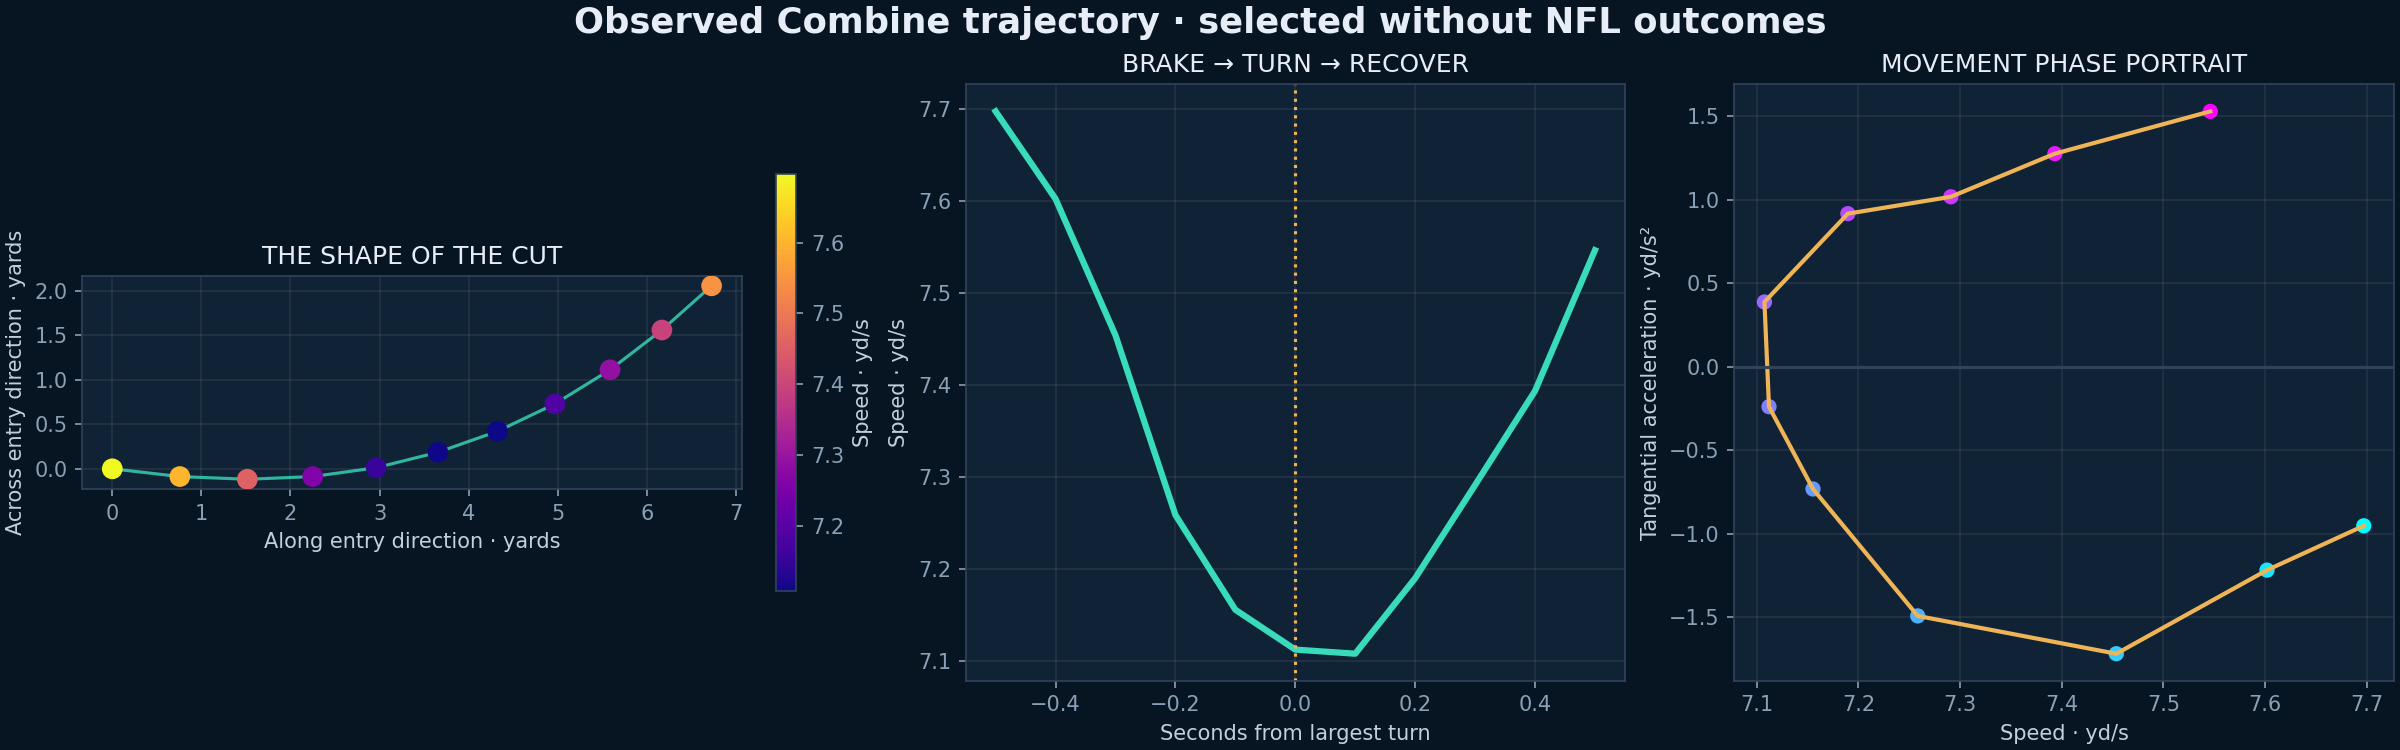

<!doctype html> Inside the cut 
 MOVEMENT LAB · FRAME BY FRAME Inside the cut. Observed Combine attempt · selected independently of NFL outcomes Canonical entry frame · yards Time from detected turn seconds Speed yards / second Braking / reacceleration yards / second² Play movement Eleven observed samples; interpolation animates the marker only. The line is the sampled path. Color indicates speed. A positive acceleration value means the athlete is regaining speed. The dot does not represent a defender or a missing NFL player.

In [5]:
if READY:
    from IPython.display import Image,display
    display(Image(filename=str(OUT/'actual_combine_geometry.png')))
    from IPython.display import HTML
    display(HTML((OUT/'actual_combine_geometry.html').read_text()))


## Figure 2 — Held-out performance and uncertainty
The primary improvement is in squared yards; model RMSE is in yards. Exploratory models remain labeled separately. A confidence interval overlapping zero supports an inconclusive statement.

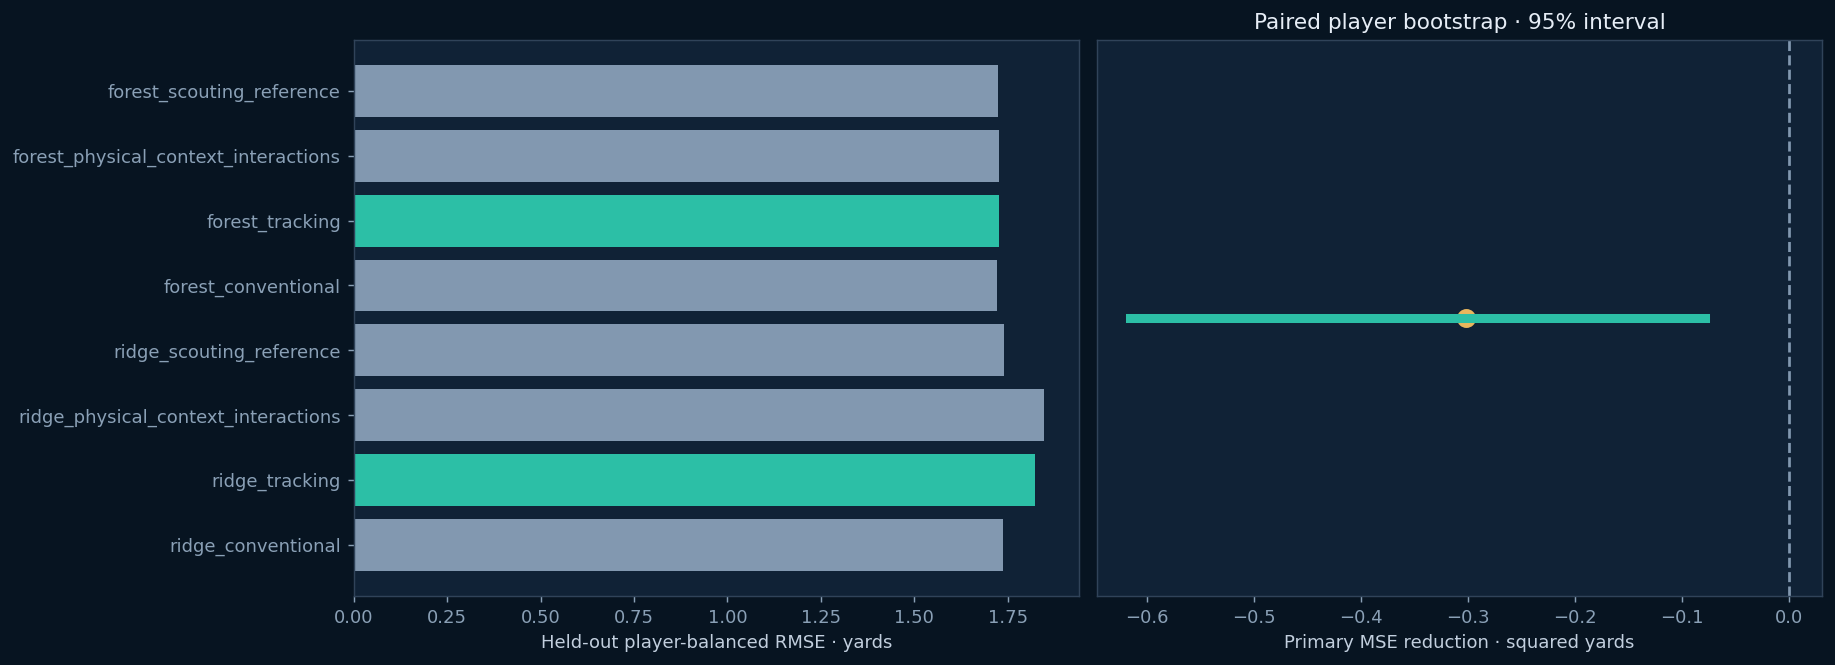

In [6]:
if report:
    import matplotlib.pyplot as plt
    names=[r['model'] for r in report['results']]
    errors=[r['test_rmse_yards'] for r in report['results']]
    fig,ax=plt.subplots(1,2,figsize=(14,5),layout='constrained')
    ax[0].barh(names,errors,color=['#2cbfa6' if 'tracking' in n else '#8298b0' for n in names]);ax[0].set_xlabel('Held-out player-balanced RMSE · yards')
    lo,hi=report['player_bootstrap_ci95'];value=report['primary_delta_mse_yards_squared']
    ax[1].plot([lo,hi],[0,0],lw=5,color='#2cbfa6');ax[1].scatter([value],[0],s=90,color='#e9b65d');ax[1].axvline(0,color='#8298b0',ls='--');ax[1].set_xlabel('Primary MSE reduction · squared yards');ax[1].set_yticks([]);ax[1].set_title('Paired player bootstrap · 95% interval')
    plt.show()


## Secondary mechanics replication
This potentially expensive cell is off by default. Turn it on only after reviewing the primary population audit. No conclusions from it enter the pre-draft model. Missing/short/straight trajectories are rejected; coverage is not reconstructed.

In [7]:
RUN_SECONDARY=True
if READY and RUN_SECONDARY:
    rows=pandas.read_pickle(OUT/'private_analysis_rows.pkl')
    print(A.game_transfer(DATA_ROOT,rows,OUT))


{'status': 'descriptive_only', 'qualifying_game_turns': 2538, 'note': 'No 22-player coverage reconstruction. Game movement is outcome-side diagnostic, never a pre-draft predictor.'}


## Figure 3 — Population and missing outcomes
Separation is available on untargeted routes as well as targets, but missingness differs. These plots describe coverage; they do not repair the bias.

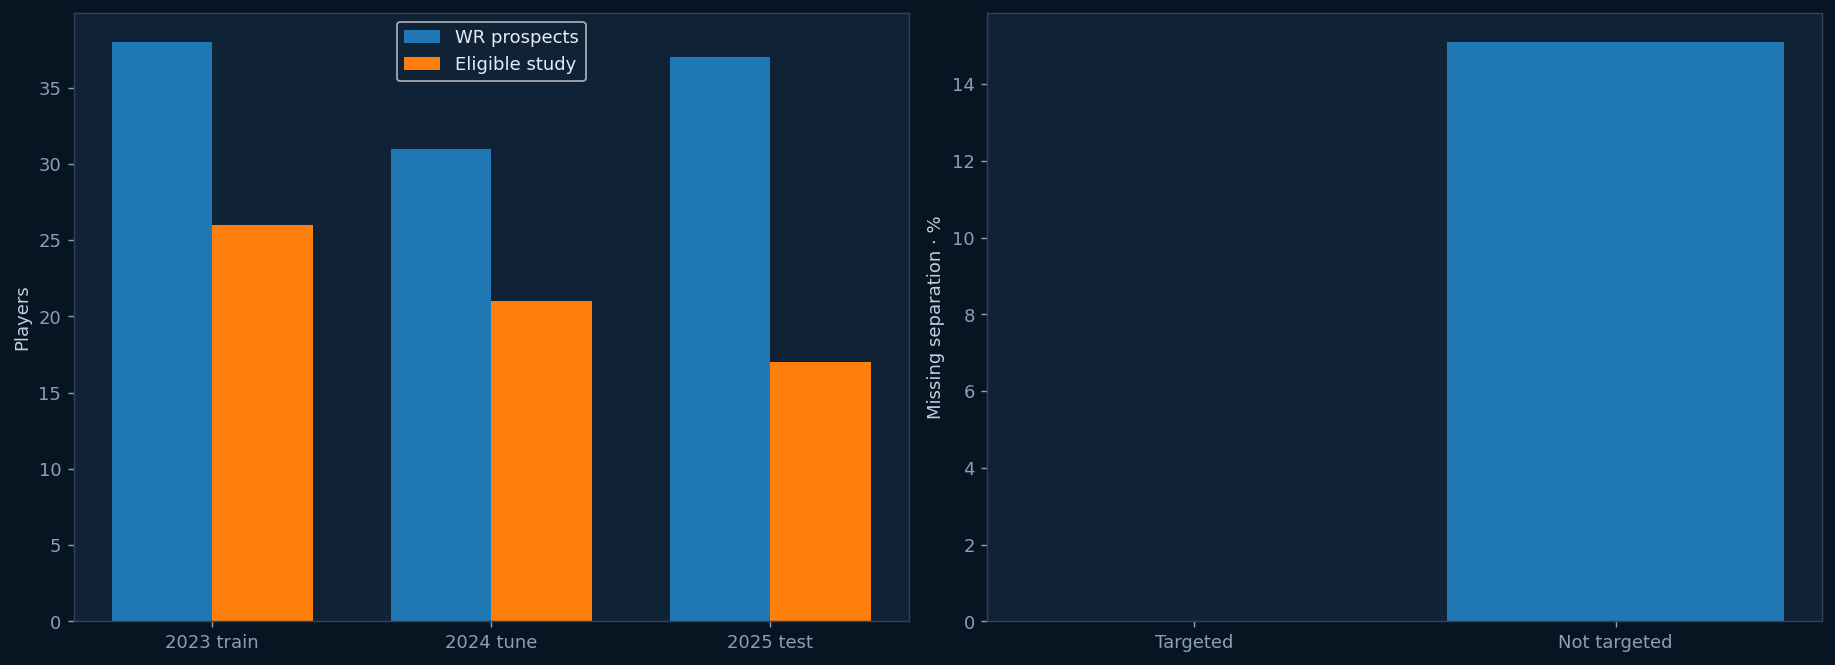

In [8]:
if READY:
    import numpy as np
    audit=json.loads((OUT/'population_audit.json').read_text())
    players=pandas.read_csv(DATA_ROOT/'players.csv');games=pandas.read_csv(DATA_ROOT/'games.csv');pp=pandas.read_csv(DATA_ROOT/'player_play.csv')
    z=pp.merge(players[['nfl_id','draft_year','nfl_position']],on='nfl_id',validate='many_to_one').merge(games[['game_id','season','season_type']],on='game_id',validate='many_to_one')
    z=z[z.nfl_position.eq('WR')&z.season.eq(z.draft_year)&z.season_type.eq('REG')&z.route_ran.isin(A.CUT_ROUTES)&z.play_nullified_by_penalty.eq('N')]
    missing=z.groupby('target').separation_at_pass_forward.apply(lambda v:float(v.isna().mean()))
    fig,ax=plt.subplots(1,2,figsize=(14,5),layout='constrained');x=np.arange(3)
    totals=players[players.nfl_position.eq('WR')].groupby('draft_year').size().reindex([2023,2024,2025]).to_numpy();kept=[audit['draft_class_players'][str(y)] for y in [2023,2024,2025]]
    ax[0].bar(x-.18,totals,.36,label='WR prospects');ax[0].bar(x+.18,kept,.36,label='Eligible study');ax[0].set_xticks(x,['2023 train','2024 tune','2025 test']);ax[0].set_ylabel('Players');ax[0].legend()
    ax[1].bar(['Targeted','Not targeted'],[100*missing.get(True,0),100*missing.get(False,0)]);ax[1].set_ylabel('Missing separation · %');plt.show()


## Figure 4 — Post-primary sensitivity and negative control
Five- and nine-frame smoothing and thirty development-player block shuffles reuse the test set as diagnostics. They cannot select a new test winner or provide a formal permutation p-value.

In [9]:
sys.modules["analysis"]=A
B=types.ModuleType("bdb_checks")
exec(compile('"""Post-primary diagnostics; cannot be used to choose a new winning test model."""\nfrom pathlib import Path\nimport json\nimport numpy as np,pandas as pd\nimport analysis as A\ndef run_checks(data,out):\n    data=Path(data);out=Path(out);d=pd.read_csv(out/\'private_analysis_rows.csv\');audit=json.loads((out/\'population_audit.json\').read_text());report=json.loads((out/\'experiment_results.json\').read_text());drill=audit[\'selected_drill\']\n    tracks=pd.read_csv(data/\'combine_tracking.csv\');tracks=tracks[tracks.entity_type.eq(\'PLAYER\')&tracks.drill_name.eq(drill)&tracks.nfl_id.isin(d.nfl_id)]\n    results=[]\n    for window in (5,7,9):\n     f=[]\n     for key,g in tracks.groupby([\'nfl_id\',\'draft_year\',\'event_id\']):\n      try:\n       row,_=A.movement(g,window);f.append(dict(nfl_id=key[0],draft_year=key[1],**row))\n      except ValueError:pass\n     agg=pd.DataFrame(f).groupby([\'nfl_id\',\'draft_year\'])[A.MOTION].median().reset_index();z=d.drop(columns=A.MOTION).merge(agg,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\')\n     if len(z)!=len(d):raise ValueError(\'smoothing changed population; do not silently change comparison\')\n     dev=z[z.draft_year.isin([2023,2024])];test=z[z.draft_year.eq(2025)];m=A.model(dev,A.BASE+A.CONTEXT+A.MOTION,\'ridge\',report[\'selection\'][\'ridge_tracking\'][\'alpha\']);m.fit(dev,dev.separation_at_pass_forward,reg__sample_weight=A.weights(dev));mse=A.score(test,m.predict(test));results.append({\'smoothing_frames\':window,\'test_mse\':mse,\'test_rmse_yards\':mse**.5,\'delta_vs_primary_baseline\':report[\'results\'][0][\'test_player_balanced_mse\']-mse})\n    # Player-block permutation in development cohorts only; labels, context and conventional predictors fixed.\n    # Evaluate on the original locked test without selecting a model from the resulting distribution.\n    dev=d[d.draft_year.isin([2023,2024])].copy();test=d[d.draft_year.eq(2025)];rng=np.random.default_rng(A.SEED);null=[]\n    for rep in range(30):\n     z=dev.copy()\n     for year in (2023,2024):\n      mask=z.draft_year.eq(year);by=z.loc[mask].groupby(\'nfl_id\')[A.MOTION].first();values=by.to_numpy()[rng.permutation(len(by))]\n      shuffled=pd.DataFrame(values,index=by.index,columns=A.MOTION)\n      for c in A.MOTION:z.loc[mask,c]=z.loc[mask,\'nfl_id\'].map(shuffled[c])\n     m=A.model(z,A.BASE+A.CONTEXT+A.MOTION,\'ridge\',report[\'selection\'][\'ridge_tracking\'][\'alpha\']);m.fit(z,z.separation_at_pass_forward,reg__sample_weight=A.weights(z));null.append(A.score(test,m.predict(test)))\n    # Calibration by player means, fit solely to test predictions as descriptive diagnostics.\n    p=pd.read_csv(out/\'private_test_predictions.csv\');q=test.merge(p,on=[\'nfl_id\',\'game_id\',\'play_id\'],validate=\'one_to_one\')\n    cal={}\n    for name in (\'ridge_conventional\',\'ridge_tracking\',\'forest_conventional\',\'forest_tracking\'):\n     by=q.groupby(\'nfl_id\')[[name,\'separation_at_pass_forward\']].mean();v=by[name].to_numpy();y=by.separation_at_pass_forward.to_numpy();slope=float(np.cov(v,y,ddof=0)[0,1]/np.var(v)) if np.var(v)>0 else None\n     cal[name]={\'player_mean_prediction_bias_yards\':float(np.mean(v-y)),\'player_mean_rmse_yards\':float(np.sqrt(np.mean((v-y)**2))),\'descriptive_calibration_slope\':slope}\n    summary={\'status\':\'actual_data_post_primary_diagnostics\',\'test_reuse_disclosed\':True,\'smoothing_sensitivity\':results,\'development_player_block_permutation\':{\'repetitions\':30,\'test_mse_values\':null,\'mean_test_mse\':float(np.mean(null)),\'scope\':\'diagnostic only; not a null-test p-value or model-selection criterion\'},\'player_mean_calibration\':cal}\n    (out/\'followup_checks.json\').write_text(json.dumps(summary,indent=2));return summary\n\nif __name__==\'__main__\':\n    root=Path(__file__).parent\n    print(json.dumps(run_checks(root/\'data\',root/\'private_results\'),indent=2))\n',"bdb_checks.py","exec"),B.__dict__)
if READY:
    diagnostics=B.run_checks(DATA_ROOT,OUT)
    print(json.dumps(diagnostics,indent=2))


{
  "status": "actual_data_post_primary_diagnostics",
  "test_reuse_disclosed": true,
  "smoothing_sensitivity": [
    {
      "smoothing_frames": 5,
      "test_mse": 3.346906802353437,
      "test_rmse_yards": 1.8294553294227867,
      "delta_vs_primary_baseline": -0.3264639895211445
    },
    {
      "smoothing_frames": 7,
      "test_mse": 3.322538728019654,
      "test_rmse_yards": 1.8227832367068921,
      "delta_vs_primary_baseline": -0.30209591518736145
    },
    {
      "smoothing_frames": 9,
      "test_mse": 3.3546945639001406,
      "test_rmse_yards": 1.8315825299178141,
      "delta_vs_primary_baseline": -0.334251751067848
    }
  ],
  "development_player_block_permutation": {
    "repetitions": 30,
    "test_mse_values": [
      3.7258677249733165,
      3.1244146905198553,
      3.0855725435057035,
      3.0186656863774566,
      3.0320414026530744,
      3.0498580165221254,
      3.023455325911532,
      2.999015870450443,
      3.157962224624781,
      3.053108345389

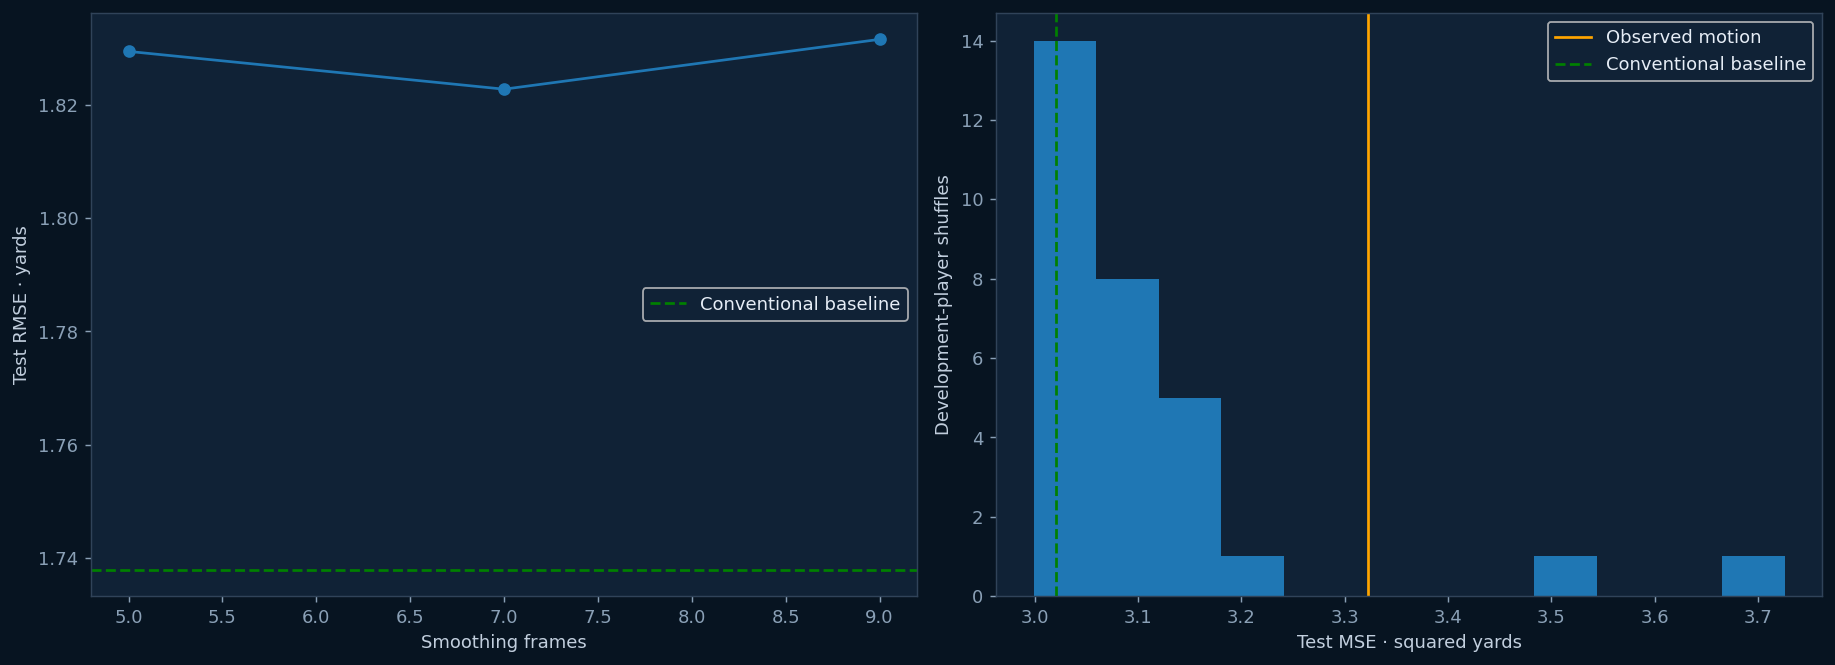

In [10]:
if READY:
    fig,ax=plt.subplots(1,2,figsize=(14,5),layout='constrained')
    ss=diagnostics['smoothing_sensitivity'];ax[0].plot([v['smoothing_frames'] for v in ss],[v['test_rmse_yards'] for v in ss],'o-');ax[0].axhline(report['results'][0]['test_rmse_yards'],ls='--',color='green',label='Conventional baseline');ax[0].set(xlabel='Smoothing frames',ylabel='Test RMSE · yards');ax[0].legend()
    ax[1].hist(diagnostics['development_player_block_permutation']['test_mse_values'],bins=12);ax[1].axvline(report['results'][1]['test_player_balanced_mse'],color='orange',label='Observed motion');ax[1].axvline(report['results'][0]['test_player_balanced_mse'],color='green',ls='--',label='Conventional baseline');ax[1].set(xlabel='Test MSE · squared yards',ylabel='Development-player shuffles');ax[1].legend();plt.show()


## Figure 5 — Do the mechanics travel?
This is descriptive across observed rookie receivers, not a causal or held-out scouting claim. Receiver medians aggregate repeated game turns; no game features enter the pre-draft model.

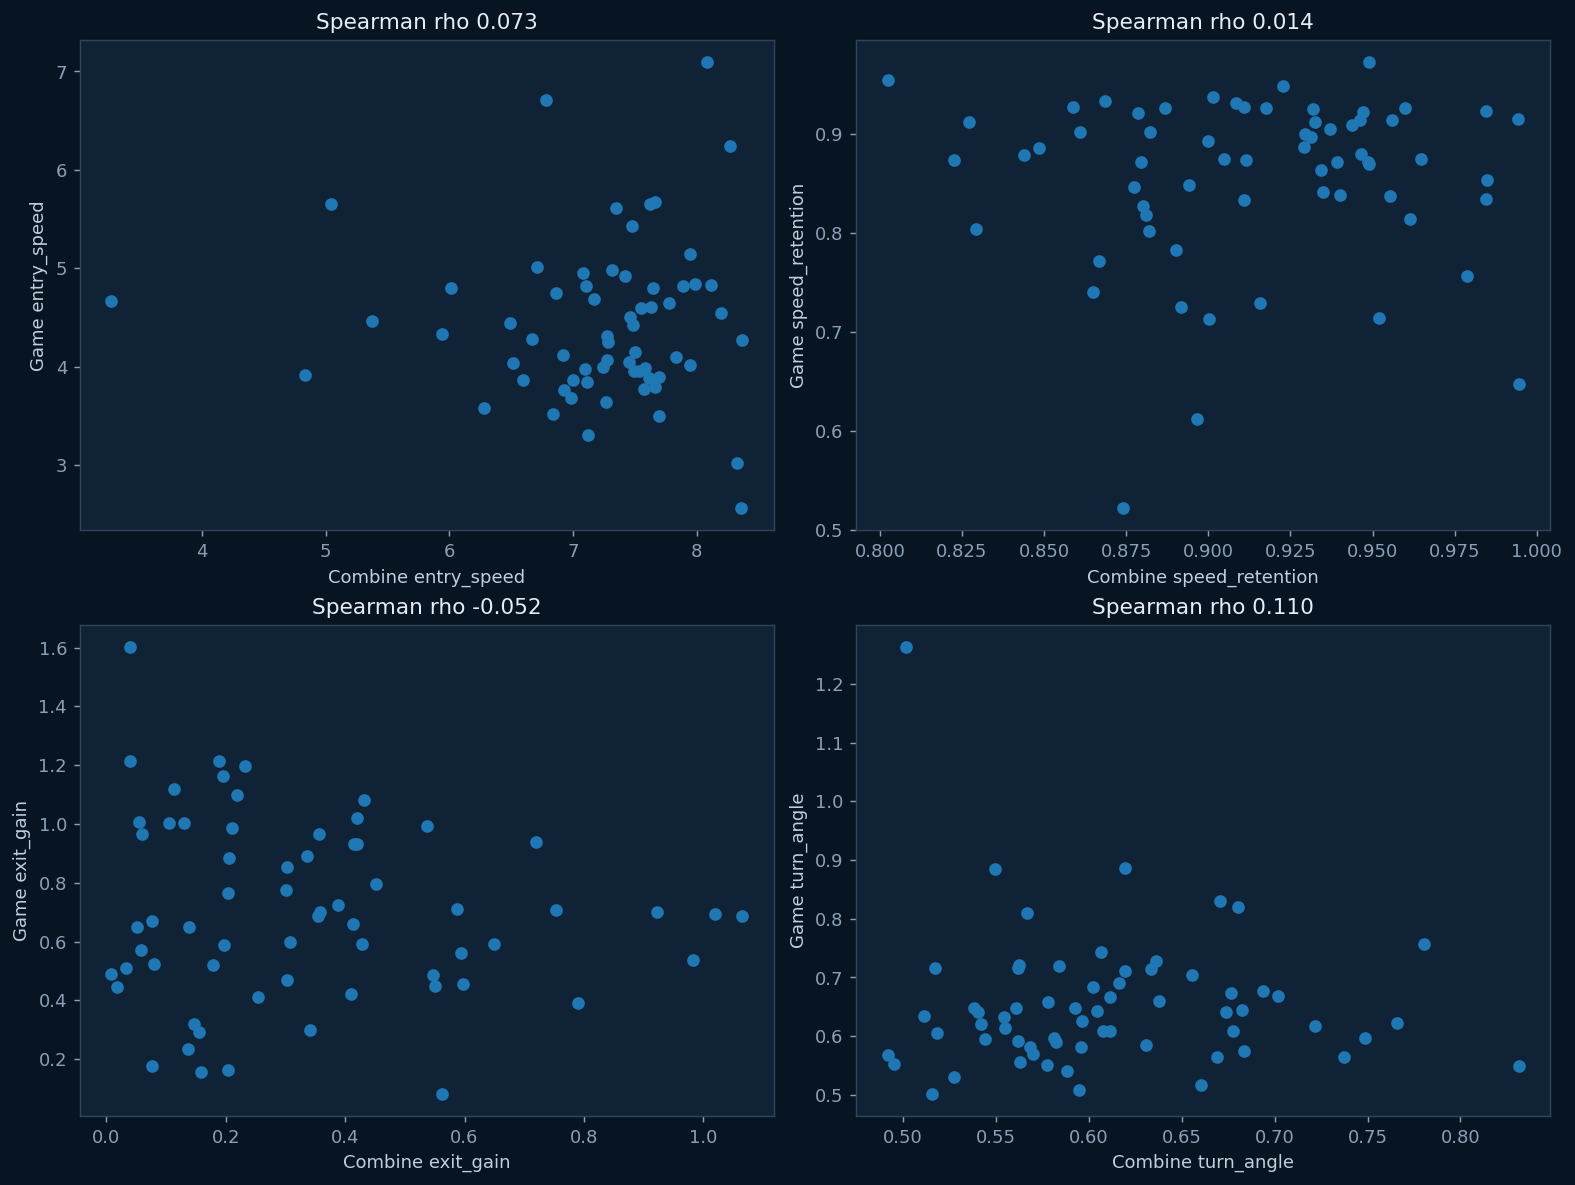

In [11]:
if READY and RUN_SECONDARY:
    from scipy.stats import spearmanr
    keys=['entry_speed','speed_retention','exit_gain','turn_angle']
    attempts=pandas.read_csv(OUT/'attempt_features.csv');selected=audit['selected_drill'];c=attempts[attempts.drill_name.eq(selected)].groupby('nfl_id')[keys].median();g=pandas.read_csv(OUT/'private_game_motion.csv').groupby('nfl_id')[keys].median();j=c.join(g,lsuffix='_combine',rsuffix='_game',how='inner')
    fig,ax=plt.subplots(2,2,figsize=(12,9),layout='constrained')
    for a,k in zip(ax.ravel(),keys):
        rho=spearmanr(j[k+'_combine'],j[k+'_game']).statistic;a.scatter(j[k+'_combine'],j[k+'_game']);a.set(xlabel='Combine '+k,ylabel='Game '+k,title=f'Spearman rho {rho:.3f}')
    plt.show()


## Repo extension — ordered movement, state memory and route-conditioned readouts
This exploratory extension uses eight shared drills and 856 predictors: cubic time/space/speed path signatures, Legendre speed modes, Hankel spectra, velocity-memory coefficients, and basic mechanics. PerfectPower’s pinned Apache-2.0 rational observable-machine implementation replays 1,109 fitted surrogate certificates and twelve source/quotient readouts each. That certifies the supplied quantized linear surrogate, not real biomechanics or scouting performance. DynaComp’s memory/Hankel architecture informed the design; no unlicensed source was copied. Prospect preprocessing and four/eight-dimensional PCA are fitted on unique training players, not repeated routes.

Five identical model candidates per family are selected using 2023 training and 2024 validation. Four outer and three inner player-group folds assess the two earlier cohorts. The drill dictionary was fixed from supplied Combine availability across all three classes; the nested fits exclude 2025 outcome labels. Because 2025 was inspected before this expansion, its new results are exploratory, not a fresh holdout.

The expanded full model has observed 2025 RMSE 1.677 yards, versus the original forest’s 1.721 and strengthened conventional model’s 1.688. The 4.98% MSE decrease relative to the original model includes better conventional predictors and learner selection. Incremental motion gain versus the strengthened comparator is 0.0377 squared yards with interval [−0.0434, 0.1099]; earlier nested validation does not confirm it. A separate route-matched experiment maps IN to Dagger, OUT to the explicit Speed Out name alias, SLANT to Slant, and HITCH to Curl/Comeback. Its small positive differences in both earlier nested and 2025 checks remain inconclusive. That changed population is evaluated only against its own matched conventional baseline. No independently established motion advantage is claimed.

In [12]:
import types,sys
vp=types.ModuleType("vendor");vp.__path__=[];sys.modules["vendor"]=vp
pp=types.ModuleType("vendor.pp");pp.__path__=[];sys.modules["vendor.pp"]=pp
m=types.ModuleType("vendor.pp.divisor_square");m.__package__="vendor.pp";sys.modules[m.__name__]=m;setattr(pp,"divisor_square",m)
exec(compile('"""Compatibility exception for the standalone observable-machine adapter.\n\nThis adapter intentionally supplies only the WorkLimit exception used by the\nunchanged upstream observable-machine module; it is not the divisor solver.\n"""\nclass WorkLimit(RuntimeError):pass\n',"divisor_square.py","exec"),m.__dict__)
m=types.ModuleType("vendor.pp.exact_linear");m.__package__="vendor.pp";sys.modules[m.__name__]=m;setattr(pp,"exact_linear",m)
exec(compile('"""Exact rational operator calculus recovered from Wilson/Forge task sections.\n\nConstructive arithmetic over Q. No integral lattice or Lean proof is inferred.\n"""\nfrom fractions import Fraction as Q\nfrom itertools import combinations\n\n\ndef matrix(rows):\n    a=tuple(tuple(row) for row in rows)\n    if not a or not a[0] or any(len(row)!=len(a[0]) for row in a):\n        raise ValueError(\'nonempty rectangular matrix required\')\n    if any(type(x) not in (int,Q) for row in a for x in row):\n        raise ValueError(\'exact integer or Fraction entries required\')\n    return tuple(tuple(map(Q,row)) for row in a)\n\n\ndef transpose(a):\n    return tuple(zip(*a))\n\n\ndef identity(n):\n    return tuple(tuple(Q(i==j) for j in range(n)) for i in range(n))\n\n\ndef multiply(a,b):\n    if not a or not b or len(a[0])!=len(b):\n        raise ValueError(\'matrix product dimension mismatch\')\n    return tuple(tuple(sum(x*y for x,y in zip(row,col)) for col in transpose(b)) for row in a)\n\n\ndef apply(a,v):\n    if not a or len(a[0])!=len(v):raise ValueError(\'vector dimension mismatch\')\n    return tuple(sum(x*y for x,y in zip(row,v)) for row in a)\n\n\ndef rref(rows,columns=None):\n    a=[list(map(Q,row)) for row in rows]\n    n=len(a[0]) if a else columns\n    if n is None:raise ValueError(\'empty system needs a column count\')\n    if any(len(row)!=n for row in a):raise ValueError(\'ragged system\')\n    pivots=[]\n    for c in range(n):\n        k=len(pivots);p=next((i for i in range(k,len(a)) if a[i][c]),None)\n        if p is None:continue\n        a[k],a[p]=a[p],a[k];v=a[k][c];a[k]=[x/v for x in a[k]]\n        for i in range(len(a)):\n            if i!=k:\n                v=a[i][c];a[i]=[x-v*y for x,y in zip(a[i],a[k])]\n        pivots.append(c)\n    return tuple(tuple(row) for row in a),tuple(pivots)\n\n\ndef rank(a):return len(rref(a)[1])\n\n\ndef kernel(a):\n    a=matrix(a);rr,piv=rref(a);n=len(a[0]);basis=[]\n    for free in range(n):\n        if free in piv:continue\n        v=[Q(0)]*n;v[free]=Q(1)\n        for i,c in enumerate(piv):v[c]=-rr[i][free]\n        basis.append(tuple(v))\n    return tuple(basis)\n\n\ndef solve(a,b):\n    a=matrix(a);b=tuple(b)\n    if len(a)!=len(b):raise ValueError(\'right-hand dimension mismatch\')\n    rr,piv=rref([list(row)+[x] for row,x in zip(a,b)]);n=len(a[0])\n    if n in piv:return None\n    v=[Q(0)]*n\n    for i,c in enumerate(piv):v[c]=rr[i][-1]\n    return tuple(v)\n\n\ndef inverse(a):\n    a=matrix(a);n=len(a)\n    if len(a[0])!=n:raise ValueError(\'square matrix required\')\n    cols=[solve(a,col) for col in transpose(identity(n))]\n    if any(c is None for c in cols):raise ValueError(\'singular matrix\')\n    return transpose(cols)\n\n\ndef _columns(vectors):return transpose(vectors)\n\n\ndef _extend(vectors,n):\n    out=list(vectors)\n    for v in identity(n):\n        if len(rref(out+[v])[1])>len(out):out.append(v)\n    if len(out)!=n:raise ValueError(\'input vectors must be independent\')\n    return tuple(out)\n\n\ndef fitting_decomposition(operator):\n    """Construct ker A^k ⊕ im A^k at the first stabilized rank, including k=0."""\n    a=matrix(operator);n=len(a)\n    if len(a[0])!=n:raise ValueError(\'square operator required\')\n    power=identity(n)\n    for k in range(n+1):\n        nxt=multiply(a,power)\n        if rank(power)==rank(nxt):break\n        power=nxt\n    else:raise AssertionError(\'rank did not stabilize\')\n    nil=kernel(power);piv=rref(power)[1];cols=transpose(power)\n    stable=tuple(cols[i] for i in piv);basis=_columns(nil+stable);inv=inverse(basis)\n    d=len(nil);diag=tuple(tuple(Q(i==j and i<d) for j in range(n)) for i in range(n))\n    projector=multiply(multiply(basis,diag),inv)\n    block=multiply(multiply(inv,a),basis)\n    if multiply(projector,projector)!=projector or multiply(a,projector)!=multiply(projector,a):\n        raise AssertionError(\'invalid Fitting projector\')\n    return {\'stabilization_index\':k,\'nilpotent_dimension\':d,\'stable_dimension\':n-d,\n            \'basis\':basis,\'inverse_basis\':inv,\'operator_in_basis\':block,\n            \'nilpotent_projector\':projector,\'stable_projector\':tuple(tuple(Q(i==j)-projector[i][j] for j in range(n)) for i in range(n)),\n            \'kernel_free\':rank(a)==n,\'execution_verified\':False,\'field\':\'Q\'}\n\n\ndef target_factor(observation,target):\n    """Construct L with target=L observation, or a concrete invisible vector."""\n    g,f=matrix(observation),matrix(target)\n    if len(g[0])!=len(f[0]):raise ValueError(\'state dimension mismatch\')\n    for v in kernel(g):\n        out=apply(f,v)\n        if any(out):\n            return {\'status\':\'AMBIGUOUS\',\'invisible_vector\':v,\'target_difference\':out,\n                    \'execution_verified\':False,\'field\':\'Q\'}\n    decoder=tuple(solve(transpose(g),row) for row in f)\n    if any(row is None for row in decoder) or multiply(decoder,g)!=f:\n        raise AssertionError(\'factorization failure\')\n    return {\'status\':\'EXACT_TARGET_FACTOR\',\'decoder\':decoder,\'execution_verified\':False,\'field\':\'Q\'}\n\n\ndef task_section(target,carrier,*,injective=False):\n    """Solve carrier T=target; construct an injective lift when requested.\n\n    Injection exists iff im(target)⊆im(carrier) and\n    dim ker(target)≤dim ker(carrier). Rational result only.\n    """\n    f,g=matrix(target),matrix(carrier)\n    if len(f)!=len(g):raise ValueError(\'common output dimension required\')\n    d,n=len(f[0]),len(g[0]);kf,kg=kernel(f),kernel(g)\n    for j,col in enumerate(transpose(f)):\n        if solve(g,col) is None:\n            witness=next(v for v in kernel(transpose(g)) if sum(x*y for x,y in zip(v,col)))\n            return {\'status\':\'IMAGE_OBSTRUCTION\',\'target_column\':j,\'left_annihilator\':witness,\n                    \'nonzero_pairing\':sum(x*y for x,y in zip(witness,col)),\'field\':\'Q\',\'execution_verified\':False}\n    if injective and len(kf)>len(kg):\n        return {\'status\':\'INJECTIVE_DIMENSION_OBSTRUCTION\',\'target_kernel_dimension\':len(kf),\n                \'carrier_kernel_dimension\':len(kg),\'field\':\'Q\',\'execution_verified\':False}\n    if injective:\n        domain=_extend(kf,d)\n        lifts=kg[:len(kf)]+tuple(solve(g,apply(f,v)) for v in domain[len(kf):])\n        t=multiply(_columns(lifts),inverse(_columns(domain)))\n    else:t=_columns(tuple(solve(g,col) for col in transpose(f)))\n    if multiply(g,t)!=f or (injective and rank(t)!=d):raise AssertionError(\'incorrect section\')\n    return {\'status\':\'INJECTIVE_TASK_SECTION\' if injective else \'TASK_SECTION\',\'lift\':t,\n            \'lift_rank\':rank(t),\'constructed_lift_integral\':all(x.denominator==1 for row in t for x in row),\n            \'target_kernel_dimension\':len(kf),\'carrier_kernel_dimension\':len(kg),\n            \'field\':\'Q\',\'execution_verified\':False}\n\n\ndef intertwiner_space(source,target,*,variable_limit=256):\n    """All T satisfying T A_i=B_i T over Q, with all contexts simultaneous.\n\n    Returns a basis of Hom, not an automatic isomorphism claim.\n    """\n    aa,bb=tuple(map(matrix,source)),tuple(map(matrix,target))\n    if not aa or len(aa)!=len(bb):raise ValueError(\'matching nonempty contexts required\')\n    n,m=len(aa[0]),len(bb[0])\n    if any(len(a)!=n or len(a[0])!=n for a in aa) or any(len(b)!=m or len(b[0])!=m for b in bb):\n        raise ValueError(\'each family needs a fixed square dimension\')\n    if type(variable_limit) is not int or variable_limit<1 or n*m>variable_limit:\n        raise ValueError(\'intertwiner variable budget exceeded\')\n    rows=[]\n    for a,b in zip(aa,bb):\n        for i in range(m):\n            for j in range(n):\n                row=[Q(0)]*(m*n)\n                for k in range(n):row[i*n+k]+=a[k][j]\n                for k in range(m):row[k*n+j]-=b[i][k]\n                rows.append(row)\n    basis=tuple(tuple(tuple(v[i*n+j] for j in range(n)) for i in range(m)) for v in kernel(rows))\n    if any(multiply(t,a)!=multiply(b,t) for t in basis for a,b in zip(aa,bb)):\n        raise AssertionError(\'invalid intertwiner\')\n    return {\'dimension\':len(basis),\'basis\':basis,\'constraint_rank\':rank(rows),\n            \'variables\':m*n,\'contexts\':len(aa),\'field\':\'Q\',\'execution_verified\':False}\n\n\ndef context_profile(contexts,*,subset_limit=1023):\n    """Ranks of vertical stacks; rank equivalence is never transport equivalence."""\n    items=tuple((name,matrix(a)) for name,a in contexts.items())\n    if not items or len({name for name,a in items})!=len(items):raise ValueError(\'named contexts required\')\n    if any(len(a[0])!=len(items[0][1][0]) for name,a in items):raise ValueError(\'common source dimension required\')\n    if type(subset_limit) is not int or (1<<len(items))-1>subset_limit:\n        raise ValueError(\'context subset budget exceeded\')\n    return [{\'contexts\':[items[i][0] for i in inds],\n             \'rank\':rank(tuple(row for i in inds for row in items[i][1]))}\n            for size in range(1,len(items)+1) for inds in combinations(range(len(items)),size)]\n\n\ndef injective_coordinates(carrier,vector):\n    """Unique coordinates in a full-column-rank rational carrier, with integrality.\n\n    A nonintegral unique coordinate rules out membership in this column lattice;\n    this conclusion is not valid for a general noninjective carrier.\n    """\n    g=matrix(carrier);v=tuple(vector)\n    if len(v)!=len(g) or any(type(x) not in (int,Q) for x in v):\n        raise ValueError(\'matching exact vector required\')\n    if rank(g)!=len(g[0]):raise ValueError(\'injective carrier required\')\n    result=task_section(tuple((x,) for x in v),g)\n    if result[\'status\']==\'IMAGE_OBSTRUCTION\':return result\n    coordinates=tuple(row[0] for row in result[\'lift\'])\n    integral=all(x.denominator==1 for x in coordinates)\n    return {\'status\':\'INTEGRAL_COORDINATES\' if integral else \'NONINTEGRAL_COORDINATES\',\n            \'coordinates\':coordinates,\'unique\':True,\'field\':\'Q\',\'execution_verified\':False,\n            \'integral_column_lattice_member\':integral}\n\n',"exact_linear.py","exec"),m.__dict__)
m=types.ModuleType("vendor.pp.observable_machine");m.__package__="vendor.pp";sys.modules[m.__name__]=m;setattr(pp,"observable_machine",m)
exec(compile('"""Exact minimal linear machines for supplied rational operator outputs.\n\nFirst restrict to states reached from the seed; then quotient directions\ninvisible to every future readout. Finite word witnesses and a nonsingular\nHankel minor certify minimal state dimension over Q, not primitive-call cost.\nWords name chronological column-vector execution, unless explicitly reversed.\n"""\nfrom fractions import Fraction as Q\nimport json\nfrom . import exact_linear as E\nfrom .divisor_square import WorkLimit\n\n\ndef _q(x):\n    if type(x) not in (int,str,Q):raise ValueError(\'exact rational entry required\')\n    v=Q(x)\n    if max(abs(v.numerator).bit_length(),v.denominator.bit_length())>8192:raise WorkLimit(\'rational entry exceeds bit budget\')\n    return v\n\n\ndef _matrix(rows,n,m):\n    a=tuple(tuple(_q(x) for x in row) for row in rows)\n    if len(a)!=n or any(len(row)!=m for row in a):raise ValueError(\'matrix shape mismatch\')\n    return a\n\n\ndef _inputs(operators,seed,readouts):\n    seed=tuple(map(_q,seed));n=len(seed);ops=tuple(operators);h=tuple(readouts)\n    if not 1<=n<=64 or not 1<=len(ops)<=16 or not 1<=len(h)<=64:raise ValueError(\'state/context/readout shape budget exceeded\')\n    return tuple(_matrix(a,n,n) for a in ops),seed,_matrix(h,len(h),n)\n\n\ndef _rank(rows):return E.rank(rows) if rows else 0\n\n\ndef _mm(a,b,n,m,k):\n    return tuple(tuple(sum(a[i][t]*b[t][j] for t in range(m)) for j in range(k)) for i in range(n))\n\n\ndef _apply(a,v):return tuple(sum(x*y for x,y in zip(row,v)) for row in a)\n\n\ndef _rows_times(row,a,n):return tuple(sum(row[t]*a[t][j] for t in range(n)) for j in range(n))\n\n\ndef _coordinate(basis,vector):\n    if not basis:\n        if any(vector):raise ValueError(\'vector outside zero span\')\n        return ()\n    c=E.solve(E.transpose(basis),vector)\n    if c is None:raise ValueError(\'vector outside supplied span\')\n    return tuple(map(_q,c))\n\n\ndef _word(ops,seed,word):\n    v=seed\n    for i in word:\n        if type(i) is not int or not 0<=i<len(ops):raise ValueError(\'invalid operator letter\')\n        v=tuple(map(_q,_apply(ops[i],v)))\n    return v\n\n\ndef _row_word(ops,row,word):\n    for i in reversed(word):\n        if type(i) is not int or not 0<=i<len(ops):raise ValueError(\'invalid operator letter\')\n        row=tuple(map(_q,_rows_times(row,ops[i],len(row))))\n    return row\n\n\ndef _det(a):\n    n=len(a);a=[list(row) for row in a];det=Q(1)\n    for j in range(n):\n        pivot=next((i for i in range(j,n) if a[i][j]),None)\n        if pivot is None:return Q(0)\n        if pivot!=j:a[j],a[pivot]=a[pivot],a[j];det=-det\n        v=a[j][j];det*=v\n        for i in range(j+1,n):\n            factor=a[i][j]/v\n            for k in range(j+1,n):a[i][k]-=factor*a[j][k]\n    return det\n\n\ndef minimal_machine(operators,seed,readouts,*,product_limit=8192):\n    ops,seed,h=_inputs(operators,seed,readouts);n=len(seed)\n    if type(product_limit) is not int or product_limit<1:raise ValueError(\'positive product budget required\')\n    basis=[];words=[];products=0\n    if any(seed):basis.append(seed);words.append(())\n    cursor=0\n    while cursor<len(basis):\n        for i,a in enumerate(ops):\n            products+=1\n            if products>product_limit:raise WorkLimit(\'reachable closure exceeds budget\')\n            v=tuple(map(_q,_apply(a,basis[cursor])))\n            if _rank(basis+[v])>len(basis):basis.append(v);words.append(words[cursor]+(i,))\n        cursor+=1\n    r=len(basis);lift=tuple(tuple(v[i] for v in basis) for i in range(n))\n    restricted=tuple(tuple(zip(*(_coordinate(basis,_apply(a,v)) for v in basis))) if r else () for a in ops)\n    restricted=tuple(_matrix(a,r,r) for a in restricted)\n    initial=_coordinate(basis,seed);hr=_mm(h,lift,len(h),n,r)\n    observations=[];row_words=[]\n    for i,row in enumerate(hr):\n        if _rank(observations+[row])>len(observations):observations.append(row);row_words.append((i,()))\n    cursor=0\n    while cursor<len(observations):\n        for i,a in enumerate(restricted):\n            products+=1\n            if products>product_limit:raise WorkLimit(\'observable closure exceeds budget\')\n            row=tuple(map(_q,_rows_times(observations[cursor],a,r)))\n            if _rank(observations+[row])>len(observations):\n                observations.append(row);output,w=row_words[cursor];row_words.append((output,(i,)+w))\n        cursor+=1\n    k=len(observations);o=tuple(observations)\n    compressed=tuple(tuple(_coordinate(o,_rows_times(row,a,r)) for row in o) for a in restricted)\n    decoder=tuple(_coordinate(o,row) for row in hr);compressed_seed=_apply(o,initial)\n    columns=E.rref(o)[1] if k else ()\n    minor=tuple(tuple(row[j] for j in columns) for row in o)\n    result={\'schema\':\'pp-observable-machine/1\',\'operators\':ops,\'seed\':seed,\'readouts\':h,\n        \'state_dimension\':n,\'reachable_dimension\':r,\'minimal_dimension\':k,\'reachable_basis\':lift,\n        \'state_words\':tuple(words),\'restricted_operators\':restricted,\'reachable_seed\':initial,\n        \'observable_rows\':o,\'readout_words\':tuple(row_words),\'operators_minimal\':compressed,\n        \'seed_minimal\':compressed_seed,\'readouts_minimal\':decoder,\'hankel_columns\':columns,\n        \'hankel_minor\':minor,\'hankel_determinant\':_det(minor),\'closure_products\':products,\n        \'word_order\':\'chronological column-vector execution\',\'field\':\'Q\',\'execution_verified\':False,\n        \'scope\':\'all finite operator words and supplied readouts; minimal linear state dimension, not integral coordinates or primitive-call optimality\'}\n    if not verify_machine(result):raise AssertionError(\'minimal machine replay failed\')\n    return result\n\n\ndef verify_machine(receipt):\n    """Check finite spanning words, closure identities and the Hankel minor.\n\n    Does not discover reachable or observable bases or perform minimization.\n    """\n    try:\n        if receipt[\'schema\']!=\'pp-observable-machine/1\' or receipt[\'field\']!=\'Q\' or receipt[\'execution_verified\'] is not False or receipt[\'word_order\']!=\'chronological column-vector execution\':return False\n        ops,seed,h=_inputs(receipt[\'operators\'],receipt[\'seed\'],receipt[\'readouts\']);n=len(seed);m=len(h)\n        r=receipt[\'reachable_dimension\'];k=receipt[\'minimal_dimension\']\n        if any(type(t) is not int for t in (r,k)) or not 0<=k<=r<=n or receipt[\'state_dimension\']!=n:return False\n        lift=_matrix(receipt[\'reachable_basis\'],n,r);words=receipt[\'state_words\']\n        restricted=tuple(_matrix(a,r,r) for a in receipt[\'restricted_operators\'])\n        initial=tuple(map(_q,receipt[\'reachable_seed\']))\n        if len(words)!=r or any(len(w)>n for w in words) or len(restricted)!=len(ops) or len(initial)!=r or _rank(E.transpose(lift))!=r:return False\n        if _apply(lift,initial)!=seed:return False\n        if any(_word(ops,seed,w)!=v for w,v in zip(words,E.transpose(lift))):return False\n        if any(_mm(a,lift,n,n,r)!=_mm(lift,b,n,r,r) for a,b in zip(ops,restricted)):return False\n        o=_matrix(receipt[\'observable_rows\'],k,r);row_words=receipt[\'readout_words\']\n        compressed=tuple(_matrix(a,k,k) for a in receipt[\'operators_minimal\']);decoder=_matrix(receipt[\'readouts_minimal\'],m,k)\n        hr=_mm(h,lift,m,n,r)\n        if _rank(o)!=k or len(row_words)!=k or len(compressed)!=len(ops):return False\n        for row,(index,word) in zip(o,row_words):\n            if type(index) is not int or not 0<=index<m or len(word)>r or _row_word(restricted,hr[index],word)!=row:return False\n        if any(_mm(o,a,k,r,r)!=_mm(b,o,k,k,r) for a,b in zip(restricted,compressed)):return False\n        if _mm(decoder,o,m,k,r)!=hr or tuple(map(_q,receipt[\'seed_minimal\']))!=_apply(o,initial):return False\n        columns=tuple(receipt[\'hankel_columns\'])\n        if len(columns)!=k or len(set(columns))!=k or any(type(j) is not int or not 0<=j<r for j in columns):return False\n        minor=tuple(tuple(row[j] for j in columns) for row in o)\n        if _matrix(receipt[\'hankel_minor\'],k,k)!=minor:return False\n        return _q(receipt[\'hankel_determinant\'])==_det(minor)!=0\n    except (ValueError,TypeError,KeyError,IndexError,ArithmeticError,OverflowError):return False\n\n\ndef word_output(receipt,word,*,order=\'execution\',original=False):\n    if not verify_machine(receipt):raise ValueError(\'invalid machine certificate\')\n    if order not in (\'execution\',\'written\'):raise ValueError(\'execution or written word order required\')\n    word=tuple(word)\n    if len(word)>4096:raise WorkLimit(\'word length exceeds budget\')\n    if order==\'written\':word=word[::-1]\n    if original:\n        ops,seed,h=_inputs(receipt[\'operators\'],receipt[\'seed\'],receipt[\'readouts\'])\n    else:\n        k=receipt[\'minimal_dimension\'];ops=tuple(_matrix(a,k,k) for a in receipt[\'operators_minimal\'])\n        seed=tuple(map(_q,receipt[\'seed_minimal\']));h=_matrix(receipt[\'readouts_minimal\'],len(receipt[\'readouts\']),k)\n    return _apply(h,_word(ops,seed,word))\n\n\ndef recurrence_batch(models):\n    """Share an exact machine across supplied Recurrence definitions."""\n    from .recurrence import Recurrence\n    from .recurrence_identity import companion\n    models=tuple(models)\n    if not models or any(not isinstance(m,Recurrence) for m in models):raise ValueError(\'nonempty supplied recurrence models required\')\n    dims=[len(m.initial) for m in models];n=sum(dims)\n    if n>64 or len(models)>64:raise WorkLimit(\'recurrence batch exceeds state budget\')\n    a=[[Q(0)]*n for _ in range(n)];h=[];seed=();offset=0\n    for model,d in zip(models,dims):\n        block=companion(model)\n        for i in range(d):a[offset+i][offset:offset+d]=block[i]\n        row=[Q(0)]*n;row[offset]=Q(1);h.append(row);seed+=model.initial;offset+=d\n    return minimal_machine([a],seed,h)\n\n\ndef power_outputs(receipt,index,*,context=0,original=False):\n    """Read a repeated operator word by exact binary powering."""\n    if not verify_machine(receipt):raise ValueError(\'invalid machine certificate\')\n    if type(index) is not int or index<0 or index.bit_length()>64:raise ValueError(\'nonnegative 64-bit index required\')\n    if type(context) is not int or not 0<=context<len(receipt[\'operators\']):raise ValueError(\'invalid operator context\')\n    if original:\n        ops,seed,h=_inputs(receipt[\'operators\'],receipt[\'seed\'],receipt[\'readouts\']);n=len(seed)\n    else:\n        n=receipt[\'minimal_dimension\'];ops=tuple(_matrix(a,n,n) for a in receipt[\'operators_minimal\'])\n        seed=tuple(map(_q,receipt[\'seed_minimal\']));h=_matrix(receipt[\'readouts_minimal\'],len(receipt[\'readouts\']),n)\n    a=ops[context];v=seed\n    while index:\n        if index&1:v=tuple(map(_q,_apply(a,v)))\n        index//=2\n        if index:a=tuple(tuple(map(_q,row)) for row in _mm(a,a,n,n,n))\n    return tuple(map(_q,_apply(h,v)))\n\n',"observable_machine.py","exec"),m.__dict__)
m=types.ModuleType("repo_motion");sys.modules["repo_motion"]=m
exec(compile('"""Multi-drill ordered geometry and observable velocity-state summaries.\n\nThe rational surrogate is checked exactly; the measured trajectory and its\nregression relationship remain numerical empirical questions.\n"""\nfrom pathlib import Path\nimport json,hashlib\nimport numpy as np,pandas as pd\nimport analysis as A\nfrom vendor.pp import observable_machine as O\n\n\ndef signature3(path):\n    path=np.asarray(path,float);dim=path.shape[1];s1=np.zeros(dim);s2=np.zeros((dim,dim));s3=np.zeros((dim,dim,dim))\n    for inc in np.diff(path,axis=0):\n        inc2=np.outer(inc,inc)/2\n        s3=s3+np.einsum(\'ij,k->ijk\',s2,inc)+np.einsum(\'i,jk->ijk\',s1,inc2)+np.einsum(\'i,j,k->ijk\',inc,inc,inc)/6\n        s2=s2+np.outer(s1,inc)+inc2;s1=s1+inc\n    return np.r_[s1,s2.ravel(),s3.ravel()]\n\n\ndef descriptors(g):\n    base,diag=A.movement(g);q=diag[\'q\'];s=diag[\'speed\'];arc=float(np.linalg.norm(np.diff(q,axis=0),axis=1).sum());entry=base[\'entry_speed\']\n    path=np.c_[diag[\'t\']+.5,q/max(arc,1e-6),s/max(entry,1e-6)]\n    sig=signature3(path);features=dict(base)\n    for i,v in enumerate(sig):features[f\'sig_{i:03d}\']=float(v)\n    grid=np.linspace(-1,1,len(s));profile=s/max(entry,1e-6)\n    for i,v in enumerate(np.polynomial.legendre.legfit(grid,profile,4)):features[f\'profile_{i}\']=float(v)\n    H=np.stack([profile[i:i+7] for i in range(5)]);sv=np.linalg.svd(H,compute_uv=False);p=sv/sv.sum();features[\'hankel_entropy\']=float(-np.sum(p*np.log(np.maximum(p,1e-12))))\n    for i,v in enumerate(p):features[f\'hankel_{i}\']=float(v)\n    # Ridge-fit two-state recurrence to normalized measured speed.\n    X=np.c_[profile[1:-1],profile[:-2]];y=profile[2:];coef=np.linalg.solve(X.T@X+1e-3*np.eye(2),X.T@y)\n    fitted=X@coef;features[\'memory_a1\']=float(coef[0]);features[\'memory_a2\']=float(coef[1]);features[\'memory_residual\']=float(np.sqrt(np.mean((y-fitted)**2)))\n    features[\'memory_radius\']=float(np.max(np.abs(np.roots([1,-coef[0],-coef[1]]))))\n    aq=[f\'{v:.4f}\' for v in coef];seed=[f\'{profile[1]:.6f}\',f\'{profile[0]:.6f}\']\n    packet=O.minimal_machine([[[aq[0],aq[1]],[1,0]]],seed,[[1,0]])\n    if not O.verify_machine(packet):raise ValueError(\'surrogate certificate rejected\')\n    # Check original and quotient forecasts agree exactly over twelve readouts.\n    for k in range(12):\n        if O.power_outputs(packet,k)!=O.power_outputs(packet,k,original=True):raise ValueError(\'source/quotient readout mismatch\')\n    return features,packet\n\n\ndef build_features(root,out,aliases=False):\n    root,out=Path(root),Path(out);out.mkdir(exist_ok=True,parents=True);players=pd.read_csv(root/\'players.csv\');ids=set(players.loc[players.nfl_position.eq(\'WR\'),\'nfl_id\']);d=pd.read_csv(root/\'combine_tracking.csv\');d=d[d.entity_type.eq(\'PLAYER\')&d.nfl_id.isin(ids)&d.drill_type.eq(\'SKILL_DRILLS_WR\')]\n    if aliases:d[\'drill_name\']=d.drill_name.replace({\'SPEED_OUT_LEFT\':\'SPEED_OUT_ROUTE_LEFT\'})\n    rows=[];rejects=0;orders={};example=None\n    for key,g in d.groupby([\'nfl_id\',\'draft_year\',\'event_id\']):\n        try:f,packet=descriptors(g)\n        except ValueError:rejects+=1;continue\n        if example is None:example=packet\n        order=packet[\'minimal_dimension\'];orders[str(order)]=orders.get(str(order),0)+1\n        rows.append(dict(nfl_id=key[0],draft_year=key[1],event_id=key[2],drill_name=g.drill_name.iloc[0],**f))\n    attempts=pd.DataFrame(rows);features=[c for c in attempts.columns if c not in [\'nfl_id\',\'draft_year\',\'event_id\',\'drill_name\']]\n    availability=attempts.groupby([\'drill_name\',\'draft_year\']).nfl_id.nunique().unstack(fill_value=0).reindex(columns=[2023,2024,2025],fill_value=0)\n    drills=sorted(availability.index[availability.min(axis=1)>=5]);attempts=attempts[attempts.drill_name.isin(drills)]\n    panel=attempts.groupby([\'nfl_id\',\'drill_name\'])[features].median().unstack(\'drill_name\');panel.columns=[f\'motion__{drill}__{feature}\' for feature,drill in panel.columns];panel=panel.reset_index()\n    panel.to_csv(out/\'private_motion_panel.csv\',index=False)\n    (out/\'private_surrogate_example.json\').write_text(json.dumps(example,default=str,indent=2))\n    audit={\'qualifying_attempts_all_drills\':len(rows),\'qualifying_shared_attempts\':len(attempts),\'shared_drills\':drills,\'players_with_features\':len(panel),\'feature_columns\':len(panel.columns)-1,\'rejected_no_cut_attempts\':rejects,\'surrogate_order_counts\':orders,\'exact_surrogate_certificates_replayed\':len(rows),\'certified_readouts_per_surrogate\':12,\'name_alias_applied\':aliases,\'scope\':\'quantized supplied surrogate only; measured trajectories and predictive skill not certified\'}\n    (out/\'feature_audit.json\').write_text(json.dumps(audit,indent=2));print(json.dumps(audit,indent=2),flush=True)\n    return panel,audit\n\nif __name__==\'__main__\':\n    root=Path(__file__).parent;build_features(root/\'data\',root/\'private_repo_results\')\n',"repo_motion.py","exec"),m.__dict__)
m=types.ModuleType("repo_predict");sys.modules["repo_predict"]=m
exec(compile('"""Prospect-balanced compression and development-only model selection.\n\n2025 was already inspected before this push; its results are exploratory.\n"""\nfrom pathlib import Path\nimport json,time\nimport numpy as np,pandas as pd\nfrom sklearn.base import BaseEstimator,TransformerMixin\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler,OneHotEncoder\nfrom sklearn.decomposition import PCA\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.linear_model import Ridge\nfrom sklearn.ensemble import RandomForestRegressor,ExtraTreesRegressor\nfrom sklearn.model_selection import StratifiedGroupKFold\nimport analysis as A\n\nPHYS=A.BASE+[\'hand_size\',\'arm_length\',\'wing_span\',\'bench_reps\',\'ngs_athleticism_score\',\'ngs_college_production_score\',\'ngs_final_score\']\nNUM=A.CONTEXT+[\'quarter\']\nCAT=A.CATS+[\'team_coverage_type\',\'receiver_alignment\',\'team_abbr\',\'defense_team\']\nCONFIGS=[{\'reg\':\'ridge\',\'alpha\':1,\'k\':4},{\'reg\':\'ridge\',\'alpha\':10,\'k\':4},{\'reg\':\'ridge\',\'alpha\':100,\'k\':8},{\'reg\':\'forest\',\'alpha\':0,\'k\':4},{\'reg\':\'extra\',\'alpha\':0,\'k\':8}]\n\nclass ProspectEncoder(BaseEstimator,TransformerMixin):\n    def __init__(self,motion=(),k=4):self.motion=motion;self.k=k\n    def fit(self,x,y=None):\n        players=x.drop_duplicates(\'nfl_id\');self.fit_player_ids_=set(players.nfl_id)\n        self.phys=Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())]);self.phys.fit(players[PHYS])\n        self.num=Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())]);self.num.fit(x[NUM])\n        self.cat=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False);self.cat.fit(x[CAT].astype(str).where(x[CAT].notna(),\'MISSING\'))\n        if self.motion:\n            m=players[list(self.motion)].to_numpy(float);self.lo=np.nanquantile(m,.01,axis=0);self.hi=np.nanquantile(m,.99,axis=0)\n            self.lo=np.nan_to_num(self.lo);self.hi=np.nan_to_num(self.hi)\n            self.mi=SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True);m=self.mi.fit_transform(np.clip(m,self.lo,self.hi));self.ms=StandardScaler();m=self.ms.fit_transform(m)\n            self.pca=PCA(n_components=min(self.k,len(players)-1,m.shape[1]),svd_solver=\'full\');self.pca.fit(m)\n        return self\n    def transform(self,x):\n        blocks=[self.phys.transform(x[PHYS]),self.num.transform(x[NUM]),self.cat.transform(x[CAT].astype(str).where(x[CAT].notna(),\'MISSING\'))]\n        if self.motion:\n            m=np.clip(x[list(self.motion)].to_numpy(float),self.lo,self.hi);blocks.append(self.pca.transform(self.ms.transform(self.mi.transform(m))))\n        return np.column_stack(blocks)\n\ndef columns(panel,family):\n    cols=[c for c in panel if c.startswith(\'motion__\')]\n    if family==\'baseline\':return ()\n    if family==\'summary\':return tuple(c for c in cols if c.split(\'__\')[-1] in A.MOTION)\n    if family==\'signature\':return tuple(c for c in cols if c.split(\'__\')[-1].startswith(\'sig_\'))\n    if family==\'dynamics\':return tuple(c for c in cols if c.split(\'__\')[-1].startswith((\'memory_\',\'hankel_\',\'profile_\')))\n    if family==\'all\':return tuple(cols)\n    raise ValueError(\'family\')\n\ndef make(motion,config):\n    enc=ProspectEncoder(motion,config[\'k\'])\n    if config[\'reg\']==\'ridge\':reg=Ridge(alpha=config[\'alpha\'])\n    elif config[\'reg\']==\'forest\':reg=RandomForestRegressor(n_estimators=150,max_depth=6,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    else:reg=ExtraTreesRegressor(n_estimators=150,max_depth=8,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    return Pipeline([(\'enc\',enc),(\'reg\',reg)])\n\ndef fit_predict(train,test,motion,config):\n    if set(train.nfl_id)&set(test.nfl_id):raise ValueError(\'player overlap\')\n    m=make(motion,config);m.fit(train,train.separation_at_pass_forward,reg__sample_weight=A.weights(train));return m,m.predict(test)\n\ndef prepare(root,out,data_root=None,analysis_out=None):\n    root,out=Path(root),Path(out);data_root=Path(data_root) if data_root else root/\'data\';analysis_out=Path(analysis_out) if analysis_out else root/\'private_results\';d=pd.read_pickle(analysis_out/\'private_analysis_rows.pkl\') if (analysis_out/\'private_analysis_rows.pkl\').exists() else pd.read_csv(analysis_out/\'private_analysis_rows.csv\');panel=pd.read_csv(out/\'private_motion_panel.csv\');d=d.drop(columns=A.MOTION).merge(panel,on=\'nfl_id\',validate=\'many_to_one\')\n    g=pd.read_csv(data_root/\'games.csv\').set_index(\'game_id\');home=d.game_id.map(g.home_team_abbr);away=d.game_id.map(g.visitor_team_abbr);d[\'defense_team\']=np.where(home==d.team_abbr,away,home)\n    if d.nfl_id.nunique()!=64 or len(d)!=7348:raise ValueError(\'frozen population changed\')\n    return d,panel\n\ndef bootstrap(test,p0,p1):\n    x=pd.DataFrame({\'id\':test.nfl_id,\'delta\':(test.separation_at_pass_forward-p0)**2-(test.separation_at_pass_forward-p1)**2}).groupby(\'id\').delta.mean().to_numpy();rng=np.random.default_rng(A.SEED);boots=rng.choice(x,(5000,len(x)),replace=True).mean(axis=1)\n    return {\'delta_mse\':float(x.mean()),\'ci95\':np.quantile(boots,[.025,.975]).tolist(),\'players\':len(x)}\n\ndef cohort_trial(root,out,data_root=None,analysis_out=None):\n    root,out=Path(root),Path(out);d,panel=prepare(root,out,data_root,analysis_out);train=d[d.draft_year.eq(2023)];val=d[d.draft_year.eq(2024)];dev=d[d.draft_year.isin([2023,2024])];test=d[d.draft_year.eq(2025)]\n    bank=[];selected={};preds={};start=time.perf_counter()\n    for family in [\'baseline\',\'summary\',\'signature\',\'dynamics\',\'all\']:\n        cc=columns(panel,family);candidates=[]\n        for i,config in enumerate(CONFIGS):\n            m,p=fit_predict(train,val,cc,config);v=A.score(val,p);candidates.append((v,i));bank.append({\'family\':family,\'config\':i,\'validation_mse\':v});print(\'Validation\',family,i,round(v,6),flush=True)\n        v,i=min(candidates);m,p=fit_predict(dev,test,cc,CONFIGS[i]);preds[family]=p;selected[family]={\'config\':CONFIGS[i],\'config_index\':i,\'validation_mse\':v,\'test_mse\':A.score(test,p),\'test_rmse_yards\':A.score(test,p)**.5,\'motion_input_columns\':len(cc),\'motion_latent_dimension\':m.named_steps[\'enc\'].pca.n_components_ if cc else 0}\n    for family in [\'summary\',\'signature\',\'dynamics\',\'all\']:selected[family][\'paired_vs_strong_conventional\']=bootstrap(test,preds[\'baseline\'],preds[family])\n    original=pd.read_csv((Path(analysis_out) if analysis_out else root/\'private_results\')/\'private_test_predictions.csv\');q=test[[\'nfl_id\',\'game_id\',\'play_id\']].merge(original,on=[\'nfl_id\',\'game_id\',\'play_id\'],validate=\'one_to_one\')\n    old=q.forest_conventional.to_numpy();selected[\'all\'][\'paired_vs_original_forest\']=bootstrap(test,old,preds[\'all\'])\n    result={\'status\':\'exploratory_actual_data\',\'test_previously_inspected\':True,\'selection\':\'2023 train; 2024 tune; refit 2023+2024; 2025 exploratory transport\',\'primary_new_family\':\'all\',\'selected\':selected,\'validation_bank\':bank,\'same_candidates_per_family\':len(CONFIGS),\'test_players\':test.nfl_id.nunique(),\'test_routes\':len(test),\'elapsed_seconds\':time.perf_counter()-start,\'interpretation\':\'Ablations exploratory; superiority requires stronger development-only corroboration and fresh future validation.\'}\n    (out/\'cohort_trial.json\').write_text(json.dumps(result,indent=2));p=test[[\'nfl_id\',\'game_id\',\'play_id\']].copy()\n    for k,v in preds.items():p[k]=v\n    p.to_csv(out/\'private_cohort_predictions.csv\',index=False);print(json.dumps(result,indent=2),flush=True);return result\n\ndef nested_development(root,out,data_root=None,analysis_out=None):\n    root,out=Path(root),Path(out);d,panel=prepare(root,out,data_root,analysis_out);dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);outer=StratifiedGroupKFold(n_splits=4,shuffle=True,random_state=A.SEED);preds={f:np.zeros(len(dev)) for f in [\'baseline\',\'all\']};receipts=[]\n    for fold,(ii,jj) in enumerate(outer.split(dev,dev.draft_year,dev.nfl_id)):\n        tr,te=dev.iloc[ii],dev.iloc[jj];inner=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=A.SEED+fold+1)\n        for family in [\'baseline\',\'all\']:\n            cc=columns(panel,family);rank=[]\n            for ci,config in enumerate(CONFIGS):\n                losses=[]\n                for a,b in inner.split(tr,tr.draft_year,tr.nfl_id):\n                    ti,vi=tr.iloc[a],tr.iloc[b];_,p=fit_predict(ti,vi,cc,config);losses.append(A.score(vi,p))\n                rank.append((float(np.mean(losses)),ci))\n            _,ci=min(rank);_,p=fit_predict(tr,te,cc,CONFIGS[ci]);preds[family][jj]=p;receipts.append({\'outer_fold\':fold,\'family\':family,\'chosen_config\':ci,\'inner_scores\':[v for v,i in rank],\'outer_mse\':A.score(te,p),\'outer_players\':te.nfl_id.nunique()});print(\'Nested\',fold,family,\'MSE\',round(A.score(te,p),6),flush=True)\n    result={\'status\':\'development_only_nested_player_validation\',\'years\':[2023,2024],\'test_2025_outcomes_used\':False,\'drill_dictionary_scope\':\'fixed using full supplied Combine drill availability, including 2025; no outcome-based selection\',\'players\':dev.nfl_id.nunique(),\'routes\':len(dev),\'baseline_mse\':A.score(dev,preds[\'baseline\']),\'motion_mse\':A.score(dev,preds[\'all\']),\'paired_improvement\':bootstrap(dev,preds[\'baseline\'],preds[\'all\']),\'fold_receipts\':receipts,\'scope\':\'unseen players in pooled earlier seasons; complements but does not replace a future-season holdout\'}\n    (out/\'nested_development.json\').write_text(json.dumps(result,indent=2));p=dev[[\'nfl_id\',\'game_id\',\'play_id\']].copy()\n    for k,v in preds.items():p[k]=v\n    p.to_csv(out/\'private_nested_predictions.csv\',index=False);print(json.dumps(result,indent=2),flush=True);return result\n\nif __name__==\'__main__\':\n    import argparse\n    ap=argparse.ArgumentParser();ap.add_argument(\'--nested\',action=\'store_true\');args=ap.parse_args();root=Path(__file__).parent;out=root/\'private_repo_results\'\n    if args.nested:nested_development(root,out)\n    else:cohort_trial(root,out)\n',"repo_predict.py","exec"),m.__dict__)
m=types.ModuleType("route_matched");sys.modules["route_matched"]=m
exec(compile('"""Exploratory route-conditioned observation of Combine movement state."""\nfrom pathlib import Path\nimport json\nimport numpy as np,pandas as pd\nfrom sklearn.decomposition import PCA\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.model_selection import StratifiedGroupKFold\nimport analysis as A,repo_predict as R\nMAP={\'IN\':[\'DAGGER_ROUTE_LEFT\'],\'OUT\':[\'SPEED_OUT_ROUTE_LEFT\'],\'SLANT\':[\'SLANT_ROUTE_LEFT\'],\'HITCH\':[\'CURL_ROUTE_RIGHT\',\'COMEBACK_ROUTE_RIGHT\']}\n\nclass RouteEncoder(R.ProspectEncoder):\n    def __init__(self,motion=(),k=4):super().__init__((),k);self.motion=motion\n    def vector(self,x,route):\n        names=sorted({c.split(\'__\')[-1] for c in self.motion});blocks=[]\n        for drill in MAP[route]:\n            blocks.append(x[[f\'motion__{drill}__{name}\' for name in names]].to_numpy(float))\n        total=np.zeros_like(blocks[0]);count=np.zeros_like(total)\n        for block in blocks:total+=np.nan_to_num(block);count+=np.isfinite(block)\n        return np.divide(total,count,out=np.full_like(total,np.nan),where=count>0)\n    def fit(self,x,y=None):\n        selected=self.motion;self.motion=();super().fit(x,y);self.motion=selected\n        players=x.drop_duplicates(\'nfl_id\');m=np.concatenate([self.vector(players,r) for r in MAP],axis=0)\n        self.lo=np.nan_to_num(np.nanquantile(m,.01,axis=0));self.hi=np.nan_to_num(np.nanquantile(m,.99,axis=0));self.mi=SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True);m=self.mi.fit_transform(np.clip(m,self.lo,self.hi));self.ms=StandardScaler();m=self.ms.fit_transform(m);self.pca=PCA(n_components=min(self.k,m.shape[0]-1,m.shape[1]),svd_solver=\'full\');self.pca.fit(m);return self\n    def transform(self,x):\n        selected=self.motion;self.motion=();base=super().transform(x);self.motion=selected;m=np.empty((len(x),len({c.split(\'__\')[-1] for c in selected})))\n        for route in MAP:\n            ix=np.flatnonzero(x.route_ran.eq(route).to_numpy());m[ix]=self.vector(x.iloc[ix],route)\n        return np.column_stack([base,self.pca.transform(self.ms.transform(self.mi.transform(np.clip(m,self.lo,self.hi))))])\n\ndef prepare(root,out,data_root=None):\n    root,out=Path(root),Path(out);data_root=Path(data_root) if data_root else root/\'data\';p=pd.read_csv(data_root/\'players.csv\');c=pd.read_csv(data_root/\'combine_results.csv\');g=pd.read_csv(data_root/\'games.csv\');d=pd.read_csv(data_root/\'player_play.csv\');panel=pd.read_csv(out/\'private_motion_panel.csv\')\n    d=d.merge(p[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\').merge(g[[\'game_id\',\'season\',\'season_type\',\'home_team_abbr\',\'visitor_team_abbr\']],on=\'game_id\',validate=\'many_to_one\')\n    d=d[d.nfl_position.eq(\'WR\')&d.season.eq(d.draft_year)&d.season_type.eq(\'REG\')&d.route_ran.isin(MAP)&d.play_nullified_by_penalty.eq(\'N\')&np.isfinite(d.separation_at_pass_forward)&d.separation_at_pass_forward.ge(0)]\n    counts=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(counts[counts>=20].index)].merge(c,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\').merge(panel,on=\'nfl_id\',validate=\'many_to_one\')\n    d[\'defense_team\']=np.where(d.team_abbr==d.home_team_abbr,d.visitor_team_abbr,d.home_team_abbr)\n    return d,panel\n\ndef fit_predict(tr,te,panel,config,matched):\n    if set(tr.nfl_id)&set(te.nfl_id):raise ValueError(\'player overlap\')\n    m=R.make(R.columns(panel,\'all\') if matched else (),config)\n    if matched:m.steps[0]=(\'enc\',RouteEncoder(R.columns(panel,\'all\'),config[\'k\']))\n    m.fit(tr,tr.separation_at_pass_forward,reg__sample_weight=A.weights(tr));return m.predict(te)\n\ndef run(root,out,data_root=None):\n    root,out=Path(root),Path(out);d,panel=prepare(root,out,data_root);tr=d[d.draft_year.eq(2023)];va=d[d.draft_year.eq(2024)];dv=d[d.draft_year.isin([2023,2024])];te=d[d.draft_year.eq(2025)];chosen={};pred={};bank=[]\n    for matched in [False,True]:\n        name=\'route_matched\' if matched else \'conventional\';candidates=[]\n        for ci,config in enumerate(R.CONFIGS):\n            p=fit_predict(tr,va,panel,config,matched);loss=A.score(va,p);candidates.append((loss,ci));bank.append({\'family\':name,\'config\':ci,\'validation_mse\':loss})\n        loss,ci=min(candidates);p=fit_predict(dv,te,panel,R.CONFIGS[ci],matched);pred[name]=p;chosen[name]={\'config\':R.CONFIGS[ci],\'validation_mse\':loss,\'exploratory_2025_mse\':A.score(te,p),\'exploratory_2025_rmse\':A.score(te,p)**.5};print(name,chosen[name],flush=True)\n    result={\'scope\':\'exploratory route-matched population; original 2025 inspection disclosed\',\'mapping\':MAP,\'players_by_class\':d.groupby(\'draft_year\').nfl_id.nunique().to_dict(),\'routes_by_class\':d.groupby(\'draft_year\').size().to_dict(),\'selected\':chosen,\'paired_improvement\':R.bootstrap(te,pred[\'conventional\'],pred[\'route_matched\']),\'validation_bank\':bank}\n    # Earlier-data nested assessment with candidate selection repeated inside each outer fold.\n    dv=dv.reset_index(drop=True);oof={k:np.zeros(len(dv)) for k in chosen};outer=StratifiedGroupKFold(n_splits=4,shuffle=True,random_state=A.SEED);folds=[]\n    for fold,(a,b) in enumerate(outer.split(dv,dv.draft_year,dv.nfl_id)):\n        a,b=dv.iloc[a],dv.iloc[b];inner=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=A.SEED+fold+1)\n        for matched in [False,True]:\n            name=\'route_matched\' if matched else \'conventional\';rank=[]\n            for ci,config in enumerate(R.CONFIGS):\n                losses=[]\n                for i,j in inner.split(a,a.draft_year,a.nfl_id):losses.append(A.score(a.iloc[j],fit_predict(a.iloc[i],a.iloc[j],panel,config,matched)))\n                rank.append((float(np.mean(losses)),ci))\n            _,ci=min(rank);p=fit_predict(a,b,panel,R.CONFIGS[ci],matched);oof[name][b.index]=p;folds.append({\'fold\':fold,\'family\':name,\'chosen_config\':ci,\'outer_mse\':A.score(b,p)});print(\'matched nested\',fold,name,round(A.score(b,p),6),flush=True)\n    result[\'nested_earlier_data\']={\'players\':dv.nfl_id.nunique(),\'routes\':len(dv),\'conventional_mse\':A.score(dv,oof[\'conventional\']),\'matched_mse\':A.score(dv,oof[\'route_matched\']),\'paired_improvement\':R.bootstrap(dv,oof[\'conventional\'],oof[\'route_matched\']),\'folds\':folds,\'test_2025_outcomes_used\':False,\'drill_dictionary_scope\':\'fixed from all supplied Combine availability; 2025 outcome labels excluded from nested fitting\'}\n    (out/\'route_matched_trial.json\').write_text(json.dumps(result,indent=2));print(json.dumps(result,indent=2),flush=True);return result\n\nif __name__==\'__main__\':\n    import repo_motion\n    root=Path(__file__).parent;out=root/\'private_repo_matched\';out.mkdir(exist_ok=True)\n    if not (out/\'private_motion_panel.csv\').exists():repo_motion.build_features(root/\'data\',out,aliases=True)\n    run(root,out)\n',"route_matched.py","exec"),m.__dict__)
m=types.ModuleType("repo_robustness");sys.modules["repo_robustness"]=m
exec(compile('"""Team-cluster diagnostic for exploratory prediction gains."""\nfrom pathlib import Path\nimport json\nimport pandas as pd,numpy as np\nimport analysis as A\n\ndef run(root,repo_out,analysis_out=None):\n    root,repo_out=Path(root),Path(repo_out);analysis_out=Path(analysis_out) if analysis_out else root/\'private_results\';d=pd.read_csv(analysis_out/\'private_analysis_rows.csv\');d=d[d.draft_year.eq(2025)];p=pd.read_csv(repo_out/\'private_cohort_predictions.csv\');old=pd.read_csv(analysis_out/\'private_test_predictions.csv\');d=d.merge(p,on=[\'nfl_id\',\'game_id\',\'play_id\'],validate=\'one_to_one\').merge(old,on=[\'nfl_id\',\'game_id\',\'play_id\'],validate=\'one_to_one\')\n    team=d.groupby(\'nfl_id\').team_abbr.agg(lambda x:x.value_counts().index[0]);results={}\n    for baseline in [\'forest_conventional\',\'baseline\']:\n        delta=(d.separation_at_pass_forward-d[baseline])**2-(d.separation_at_pass_forward-d[\'all\'])**2\n        players=pd.DataFrame({\'id\':d.nfl_id,\'delta\':delta}).groupby(\'id\').delta.mean().to_frame();players[\'team\']=team;groups=players.groupby(\'team\').delta.agg([\'sum\',\'count\']);rng=np.random.default_rng(A.SEED);ix=rng.integers(0,len(groups),(5000,len(groups)));s=groups[\'sum\'].to_numpy();n=groups[\'count\'].to_numpy();b=s[ix].sum(axis=1)/n[ix].sum(axis=1);results[baseline]={\'delta_mse\':float(players.delta.mean()),\'team_cluster_ci95\':np.quantile(b,[.025,.975]).tolist(),\'teams\':len(groups),\'players\':len(players)}\n    result={\'scope\':\'exploratory after 2025 inspection; dominant team clusters approximate dependence, not a season bootstrap\',\'comparisons\':results};(repo_out/\'team_cluster_diagnostic.json\').write_text(json.dumps(result,indent=2));return result\nif __name__==\'__main__\':\n    root=Path(__file__).parent;print(json.dumps(run(root,root/\'private_repo_results\'),indent=2))\n',"repo_robustness.py","exec"),m.__dict__)
m=types.ModuleType("mechanism");sys.modules["mechanism"]=m
exec(compile('"""Exploratory, player-cross-fitted context residuals and three-second mechanics.\n\nNo 2025 labels select features, regularization, or nuisance specifications.\nEarlier experiments already inspected 2025, so transport remains exploratory.\n"""\nfrom pathlib import Path\nimport json\nimport numpy as np\nimport pandas as pd\nfrom scipy.signal import savgol_filter\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.pipeline import make_pipeline\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler, OneHotEncoder\nfrom sklearn.ensemble import ExtraTreesRegressor\nfrom sklearn.linear_model import Ridge\nfrom sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold\nimport analysis as A\nimport repo_predict as R\n\nMAP={\'IN\':[\'DAGGER_ROUTE_LEFT\'],\'OUT\':[\'SPEED_OUT_ROUTE_LEFT\'],\n     \'SLANT\':[\'SLANT_ROUTE_LEFT\'],\'HITCH\':[\'CURL_ROUTE_RIGHT\',\'COMEBACK_ROUTE_RIGHT\']}\nFEATURES=[\'entry\',\'retention\',\'recovery\',\'braking\',\'propulsion\',\'turn\',\'bend\',\n          \'area\',\'speed_mode_1\',\'speed_mode_2\',\'speed_mode_3\',\'speed_mode_4\']\nALPHAS=[10.,100.,1000.]\n\ndef trajectory(g):\n    _,diag=A.movement(g)\n    g=g.sort_values(\'time\');c=diag[\'cut_index\']\n    if c<15 or c+15>=len(g):raise ValueError(\'insufficient three-second turn window\')\n    p=savgol_filter(g[[\'x\',\'y\']].to_numpy(float),7,3,axis=0)\n    v=np.gradient(p,.1,axis=0);s=np.linalg.norm(v,axis=1)\n    th=np.unwrap(np.arctan2(v[:,1],v[:,0]));sl=slice(c-15,c+16)\n    tangent=v[c-5]/max(s[c-5],1e-9);normal=np.array([-tangent[1],tangent[0]])\n    q=(p[sl]-p[c-15])@np.stack([tangent,normal],axis=1)\n    turn=th[c+5]-th[c-5];q[:,1]*=1 if turn>=0 else -1\n    speed=s[sl];acc=np.gradient(speed,.1);entry=float(speed[5:11].mean())\n    if entry<1:raise ValueError(\'insufficient approach speed\')\n    arc=np.linalg.norm(np.diff(q,axis=0),axis=1).sum()\n    mode=np.polynomial.legendre.legfit(np.linspace(-1,1,31),speed/entry,4)\n    area=.5*np.sum(q[:-1,0]*q[1:,1]-q[:-1,1]*q[1:,0])/max(arc**2,1e-9)\n    vals=[entry,float(speed[10:21].min()/entry),float(speed[21:27].mean()/entry),\n          float(np.trapezoid(np.maximum(-acc[5:21],0),dx=.1)/entry),\n          float(np.trapezoid(np.maximum(acc[15:27],0),dx=.1)/entry),abs(float(turn)),\n          float(np.trapezoid(np.gradient(th,.1)[sl]**2/np.maximum(speed,1),dx=.1)),\n          area,*mode[1:]]\n    return dict(zip(FEATURES,map(float,vals))),{\'q\':q,\'speed\':speed,\'t\':np.arange(-15,16)*.1}\n\ndef prepare(data,out):\n    data,out=Path(data),Path(out);out.mkdir(parents=True,exist_ok=True)\n    players=pd.read_csv(data/\'players.csv\');tr=pd.read_csv(data/\'combine_tracking.csv\')\n    tr=tr[tr.nfl_id.isin(players.loc[players.nfl_position.eq(\'WR\'),\'nfl_id\'])&tr.entity_type.eq(\'PLAYER\')&tr.drill_type.eq(\'SKILL_DRILLS_WR\')].copy()\n    tr[\'drill_name\']=tr.drill_name.replace({\'SPEED_OUT_LEFT\':\'SPEED_OUT_ROUTE_LEFT\'})\n    attempts=[];rejections={};example=None\n    for key,g in tr.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        if g.drill_name.iloc[0] not in {x for v in MAP.values() for x in v}:continue\n        try:f,diag=trajectory(g)\n        except ValueError as e:rejections[str(e)]=rejections.get(str(e),0)+1;continue\n        if example is None:example=diag\n        attempts.append(dict(nfl_id=key[0],drill_name=g.drill_name.iloc[0],**f))\n    feats=pd.DataFrame(attempts).groupby([\'nfl_id\',\'drill_name\'])[FEATURES].median()\n    blocks=[]\n    for route,drills in MAP.items():\n        b=feats.loc[feats.index.get_level_values(\'drill_name\').isin(drills)].groupby(\'nfl_id\').mean().reset_index();b[\'route_ran\']=route;blocks.append(b)\n    panel=pd.concat(blocks,ignore_index=True)\n    d=pd.read_csv(data/\'player_play.csv\').merge(players[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\')\n    games=pd.read_csv(data/\'games.csv\');d=d.merge(games[[\'game_id\',\'season\',\'season_type\',\'home_team_abbr\',\'visitor_team_abbr\']],on=\'game_id\',validate=\'many_to_one\')\n    eligible=d[d.nfl_position.eq(\'WR\')&d.season.eq(d.draft_year)&d.season_type.eq(\'REG\')&d.route_ran.isin(MAP)&d.play_nullified_by_penalty.eq(\'N\')].copy()\n    missing=eligible.groupby([\'draft_year\',\'team_coverage_man_zone\']).separation_at_pass_forward.apply(lambda x:float(x.isna().mean()))\n    d=eligible[np.isfinite(eligible.separation_at_pass_forward)&eligible.separation_at_pass_forward.ge(0)].copy()\n    counts=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(counts[counts>=20].index)]\n    d=d.merge(pd.read_csv(data/\'combine_results.csv\'),on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\').merge(panel,on=[\'nfl_id\',\'route_ran\'],how=\'left\',validate=\'many_to_one\')\n    d[\'defense_team\']=np.where(d.team_abbr.eq(d.home_team_abbr),d.visitor_team_abbr,d.home_team_abbr)\n    d=d.reset_index(drop=True);d.to_pickle(out/\'private_rows.pkl\')\n    audit={\'players_by_class\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').nfl_id.nunique().items()},\'routes_by_class\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').size().items()},\'accepted_attempts\':len(attempts),\'rejected_attempts\':rejections,\'missing_movement_fraction\':float(d.entry.isna().mean()),\'missing_separation_by_class_coverage\':{str(k):v for k,v in missing.items()},\'movement_window_seconds\':3,\'features\':FEATURES,\'mapping\':MAP,\'feature_selection\':\'fixed mechanics and drill mapping; no outcome-directed selection\'}\n    (out/\'mechanism_population.json\').write_text(json.dumps(audit,indent=2))\n    if example:\n        import matplotlib;matplotlib.use(\'Agg\')\n        import matplotlib.pyplot as plt\n        fig,ax=plt.subplots(1,2,figsize=(12,4),layout=\'constrained\')\n        q=example[\'q\'];sc=ax[0].scatter(q[:,0],q[:,1],c=example[\'speed\'],cmap=\'viridis\');ax[0].plot(q[:,0],q[:,1],alpha=.4);ax[0].set_aspect(\'equal\');ax[0].set(xlabel=\'Entry direction · yards\',ylabel=\'Across entry · yards\',title=\'Three-second measured turn\');fig.colorbar(sc,ax=ax[0],label=\'Speed · yd/s\')\n        ax[1].plot(example[\'t\'],example[\'speed\'],lw=3);ax[1].axvline(0,ls=\':\',color=\'gray\');ax[1].set(xlabel=\'Seconds from detected cut\',ylabel=\'Speed · yd/s\',title=\'Approach, brake and recover\')\n        fig.savefig(out/\'mechanism_geometry.png\',dpi=160);plt.close(fig)\n    return d,audit\n\ndef nuisance():\n    num=make_pipeline(SimpleImputer(strategy=\'median\',add_indicator=True),StandardScaler())\n    cat=make_pipeline(SimpleImputer(strategy=\'most_frequent\'),OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False))\n    pre=ColumnTransformer([(\'num\',num,R.NUM),(\'cat\',cat,R.CAT)])\n    return make_pipeline(pre,ExtraTreesRegressor(n_estimators=100,max_depth=6,min_samples_leaf=20,max_features=.8,random_state=A.SEED,n_jobs=2))\n\ndef crossfit(tr,te,seed):\n    assert not(set(tr.nfl_id)&set(te.nfl_id))\n    oof=np.zeros(len(tr));folds=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=seed)\n    for a,b in folds.split(tr,tr.draft_year,tr.nfl_id):\n        m=nuisance();m.fit(tr.iloc[a],tr.iloc[a].separation_at_pass_forward,extratreesregressor__sample_weight=A.weights(tr.iloc[a]));oof[b]=m.predict(tr.iloc[b])\n    m=nuisance();m.fit(tr,tr.separation_at_pass_forward,extratreesregressor__sample_weight=A.weights(tr))\n    z=tr.copy();z[\'residual\']=z.separation_at_pass_forward-oof\n    # Equal total influence per prospect; multiple route/coverage means are partial pooling units.\n    cols=R.PHYS+FEATURES\n    groups=z.groupby([\'nfl_id\',\'route_ran\',\'team_coverage_man_zone\'],dropna=False)\n    agg=groups[cols+[\'residual\']].mean().reset_index()\n    return agg,m.predict(te)\n\ndef correction(agg,te,alpha,motion):\n    cols=R.PHYS+(FEATURES if motion else [])\n    # Fit scaling only on one record per player/route/coverage; no held-out features.\n    p=make_pipeline(SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True),StandardScaler())\n    x=p.fit_transform(agg[cols]);xt=p.transform(te[cols])\n    cats=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False);c=cats.fit_transform(agg[[\'route_ran\',\'team_coverage_man_zone\']].fillna(\'MISSING\'));ct=cats.transform(te[[\'route_ran\',\'team_coverage_man_zone\']].fillna(\'MISSING\'))\n    if motion:\n        # Predefined physical and coverage interactions, after train-only scaling.\n        j=cols.index(\'combine_weight\');k=len(R.PHYS);man=agg.team_coverage_man_zone.eq(\'MAN_COVERAGE\').to_numpy()[:,None];mant=te.team_coverage_man_zone.eq(\'MAN_COVERAGE\').to_numpy()[:,None]\n        x=np.c_[x,x[:,k:k+len(FEATURES)]*x[:,j,None],x[:,k:k+len(FEATURES)]*man]\n        xt=np.c_[xt,xt[:,k:k+len(FEATURES)]*xt[:,j,None],xt[:,k:k+len(FEATURES)]*mant]\n    m=Ridge(alpha=alpha);m.fit(np.c_[x,c],agg.residual,sample_weight=A.weights(agg));return m.predict(np.c_[xt,ct])\n\ndef run(data,out):\n    out=Path(out);d,audit=prepare(data,out);dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True)\n    preds={k:np.zeros(len(dev)) for k in [\'context\',\'physical\',\'motion\']};records=[]\n    outer=StratifiedGroupKFold(n_splits=4,shuffle=True,random_state=A.SEED+80)\n    for fold,(a,b) in enumerate(outer.split(dev,dev.draft_year,dev.nfl_id)):\n        tr,te=dev.iloc[a].reset_index(drop=True),dev.iloc[b];losses={k:np.zeros(len(ALPHAS)) for k in [\'physical\',\'motion\']}\n        inner=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=A.SEED+81+fold)\n        for i,j in inner.split(tr,tr.draft_year,tr.nfl_id):\n            ti,vi=tr.iloc[i].reset_index(drop=True),tr.iloc[j];agg,base=crossfit(ti,vi,A.SEED+90+fold)\n            for family in losses:\n                for ci,alpha in enumerate(ALPHAS):losses[family][ci]+=A.score(vi,base+correction(agg,vi,alpha,family==\'motion\'))/3\n        agg,base=crossfit(tr,te,A.SEED+100+fold);preds[\'context\'][b]=base\n        for family in losses:\n            ci=int(np.argmin(losses[family]));p=base+correction(agg,te,ALPHAS[ci],family==\'motion\');preds[family][b]=p;records.append({\'fold\':fold,\'family\':family,\'alpha\':ALPHAS[ci],\'inner_mse\':losses[family].tolist(),\'outer_mse\':A.score(te,p)})\n        print(\'Mechanism outer\',fold,{k:round(A.score(te,preds[k][b]),6) for k in preds},flush=True)\n    nested={\'mse\':{k:A.score(dev,p) for k,p in preds.items()},\'paired_motion_increment\':R.bootstrap(dev,preds[\'physical\'],preds[\'motion\']),\'folds\':records,\'players\':int(dev.nfl_id.nunique()),\'routes\':len(dev)}\n    # Forward-cohort selection, then refit earlier years; no 2025 tuning.\n    tr=dev[dev.draft_year.eq(2023)].reset_index(drop=True);va=dev[dev.draft_year.eq(2024)];agg,base=crossfit(tr,va,A.SEED+200);chosen={}\n    for family in [\'physical\',\'motion\']:\n        losses=[A.score(va,base+correction(agg,va,alpha,family==\'motion\')) for alpha in ALPHAS];ci=int(np.argmin(losses));chosen[family]={\'alpha\':ALPHAS[ci],\'validation_mse\':losses}\n    agg,base=crossfit(dev,test,A.SEED+201);tp={\'context\':base}\n    for family in chosen:tp[family]=base+correction(agg,test,chosen[family][\'alpha\'],family==\'motion\')\n    transport={\'mse\':{k:A.score(test,p) for k,p in tp.items()},\'paired_motion_increment\':R.bootstrap(test,tp[\'physical\'],tp[\'motion\']),\'selection\':chosen,\'players\':int(test.nfl_id.nunique()),\'routes\':len(test)}\n    subsets={}\n    for label,rows,pp in [(\'nested\',dev,preds),(\'exploratory_2025\',test,tp)]:\n        mask=rows.team_coverage_man_zone.eq(\'MAN_COVERAGE\');n=rows[mask].groupby(\'nfl_id\').size();mask&=rows.nfl_id.isin(n[n>=5].index)\n        subsets[label]={\'man_coverage_players\':int(rows[mask].nfl_id.nunique()),\'man_coverage_routes\':int(mask.sum()),\'paired_motion_increment\':R.bootstrap(rows[mask],pp[\'physical\'][mask],pp[\'motion\'][mask])}\n    result={\'status\':\'completed_actual_data_exploratory\',\'population\':audit,\'nested_development\':nested,\'exploratory_2025\':transport,\'predefined_man_subset\':subsets,\'limitations\':[\'2025 previously inspected; no fresh holdout\',\'Residual targets are cross-fitted by player, not causal receiver effects\',\'Context-only nuisance fixed before this run; identical three-alpha selection budgets\',\'No correction for unmeasured quarterback, defender ability, or missing-not-at-random outcomes\',\'Earlier nested folds overlap prior research; this is corroboration, not independent confirmatory evidence\']}\n    (out/\'mechanism_results.json\').write_text(json.dumps(result,indent=2));print(json.dumps(result,indent=2),flush=True)\n    plot(result,out/\'mechanism_results.png\')\n    return result\n\ndef plot(result,path):\n    import matplotlib;matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    fig,ax=plt.subplots(1,2,figsize=(14,5),layout=\'constrained\')\n    for i,(name,key) in enumerate([(\'Earlier nested players\',\'nested_development\'),(\'Exploratory 2025\',\'exploratory_2025\')]):\n        vals=result[key][\'mse\'];ax[0].bar(np.arange(3)+i*.36,[np.sqrt(vals[k]) for k in [\'context\',\'physical\',\'motion\']],width=.34,label=name)\n    ax[0].set_xticks(np.arange(3)+.18,[\'Context only\',\'+ Conventional\',\'+ Mechanics\']);ax[0].set(ylabel=\'Player-balanced RMSE · yards\',title=\'Cross-fitted receiver contribution\');ax[0].legend()\n    vals=[result[\'nested_development\'][\'paired_motion_increment\'],result[\'exploratory_2025\'][\'paired_motion_increment\'],result[\'predefined_man_subset\'][\'nested\'][\'paired_motion_increment\'],result[\'predefined_man_subset\'][\'exploratory_2025\'][\'paired_motion_increment\']]\n    for i,v in enumerate(vals):ax[1].plot(v[\'ci95\'],[i,i],lw=4);ax[1].scatter(v[\'delta_mse\'],i,s=70)\n    ax[1].set_yticks(range(4),[\'Nested · all coverage\',\'2025 · all coverage\',\'Nested · man coverage\',\'2025 · man coverage\']);ax[1].axvline(0,color=\'gray\',ls=\':\');ax[1].set(xlabel=\'Conventional − mechanics MSE · yd²\',title=\'Positive favors mechanics; intervals are exploratory\')\n    fig.savefig(path,dpi=160);plt.close(fig)\n\ndef player_splits(rows,n_splits,seed):\n    """Randomize unique players within class, rather than near-fixed route counts."""\n    players=rows[[\'nfl_id\',\'draft_year\']].drop_duplicates().reset_index(drop=True)\n    if players.nfl_id.duplicated().any():raise ValueError(\'player spans multiple classes\')\n    split=StratifiedKFold(n_splits=n_splits,shuffle=True,random_state=seed)\n    for a,b in split.split(players,players.draft_year):\n        yield np.flatnonzero(rows.nfl_id.isin(players.iloc[a].nfl_id)),np.flatnonzero(rows.nfl_id.isin(players.iloc[b].nfl_id))\n\ndef split_stability(data,out):\n    """Repeat full nested selection; report conditional intervals and split variation."""\n    out=Path(out);d=pd.read_pickle(out/\'private_rows.pkl\');dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True)\n    results=[];deltas=[];partition_hashes=[]\n    for repeat in range(3):\n        seed=A.SEED+80+200*repeat;pred={k:np.zeros(len(dev)) for k in [\'context\',\'physical\',\'motion\']}\n        folds=list(player_splits(dev,4,seed))\n        import hashlib\n        partition_hashes.append(hashlib.sha256(json.dumps([sorted(map(int,dev.iloc[b].nfl_id.unique())) for a,b in folds]).encode()).hexdigest())\n        for fold,(a,b) in enumerate(folds):\n            tr,te=dev.iloc[a].reset_index(drop=True),dev.iloc[b];loss={k:np.zeros(3) for k in [\'physical\',\'motion\']}\n            for i,j in player_splits(tr,3,seed+1+fold):\n                agg,base=crossfit(tr.iloc[i].reset_index(drop=True),tr.iloc[j],seed+10+fold)\n                for family in loss:\n                    for ci,alpha in enumerate(ALPHAS):loss[family][ci]+=A.score(tr.iloc[j],base+correction(agg,tr.iloc[j],alpha,family==\'motion\'))/3\n            agg,base=crossfit(tr,te,seed+20+fold);pred[\'context\'][b]=base\n            for family in loss:pred[family][b]=base+correction(agg,te,ALPHAS[int(np.argmin(loss[family]))],family==\'motion\')\n        delta=pd.DataFrame({\'id\':dev.nfl_id,\'delta\':(dev.separation_at_pass_forward-pred[\'physical\'])**2-(dev.separation_at_pass_forward-pred[\'motion\'])**2}).groupby(\'id\').delta\n        deltas.append(delta.mean().to_numpy());results.append({\'outer_seed\':seed,\'mse\':{k:A.score(dev,p) for k,p in pred.items()},\'paired_motion_increment\':R.bootstrap(dev,pred[\'physical\'],pred[\'motion\'])})\n        print(\'Split stability\',repeat,results[-1],flush=True)\n    x=np.mean(deltas,axis=0);rng=np.random.default_rng(A.SEED);ci=np.quantile(rng.choice(x,(5000,len(x)),replace=True).mean(axis=1),[.025,.975])\n    if len(set(partition_hashes))!=3:raise ValueError(\'repeat partitions did not change\')\n    result={\'repeated_nested_results\':results,\'partition_hashes\':partition_hashes,\'split_method\':\'Stratify unique players by draft year, then map all their routes to each fold\',\'mean_player_delta_mse\':float(x.mean()),\'conditional_player_ci95\':ci.tolist(),\'positive_split_count\':int(sum(r[\'paired_motion_increment\'][\'delta_mse\']>0 for r in results)),\'scope\':\'Repeated folds share players; these are not three independent studies. Bootstrap averages each player across splits and conditions on fitted folds.\'}\n    (out/\'mechanism_split_stability.json\').write_text(json.dumps(result,indent=2));return result\n\nif __name__==\'__main__\':\n    root=Path(__file__).parent;run(root/\'data\',root/\'private_mechanism\')\n',"mechanism.py","exec"),m.__dict__)


In [13]:
if READY:
    import repo_motion as RM,repo_predict as RP,route_matched as RT,repo_robustness as RR
    REPO_OUT=OUT.parent/'private_repo_results';MATCH_OUT=OUT.parent/'private_repo_matched'
    RM.build_features(DATA_ROOT,REPO_OUT)
    repo_cohort=RP.cohort_trial(OUT.parent,REPO_OUT,data_root=DATA_ROOT,analysis_out=OUT)
    repo_nested=RP.nested_development(OUT.parent,REPO_OUT,data_root=DATA_ROOT,analysis_out=OUT)
    RM.build_features(DATA_ROOT,MATCH_OUT,aliases=True)
    matched_trial=RT.run(OUT.parent,MATCH_OUT,data_root=DATA_ROOT)
    team_diagnostic=RR.run(OUT.parent,REPO_OUT,analysis_out=OUT)
    print(json.dumps(team_diagnostic,indent=2))


{
  "qualifying_attempts_all_drills": 1109,
  "qualifying_shared_attempts": 837,
  "shared_drills": [
    "COMEBACK_ROUTE_RIGHT",
    "CURL_ROUTE_RIGHT",
    "DAGGER_ROUTE_LEFT",
    "GAUNTLET_DRILL",
    "RED_ZONE_FADE_RIGHT",
    "SLANT_ROUTE_LEFT",
    "SLOT_SAIL_ROUTE_RIGHT",
    "SLOT_STRIKE_ROUTE_LEFT"
  ],
  "players_with_features": 106,
  "feature_columns": 856,
  "rejected_no_cut_attempts": 404,
  "surrogate_order_counts": {
    "2": 1109
  },
  "exact_surrogate_certificates_replayed": 1109,
  "certified_readouts_per_surrogate": 12,
  "name_alias_applied": false,
  "scope": "quantized supplied surrogate only; measured trajectories and predictive skill not certified"
}
Validation baseline 0 2.944893
Validation baseline 1 3.049976
Validation baseline 2 3.388592
Validation baseline 3 2.933024
Validation baseline 4 2.937173
Validation summary 0 2.967965
Validation summary 1 3.086147
Validation summary 2 3.430959
Validation summary 3 2.953282
Validation summary 4 2.962825
Validatio

## Figure 6 — Improvement over the previous version; uncertain incremental motion benefit
Left: comparable observations from the original five-route population. Right: paired motion increments for each specified study, with its own population. All intervals shown are exploratory; the route-matched population differs and is not ranked against the original task.

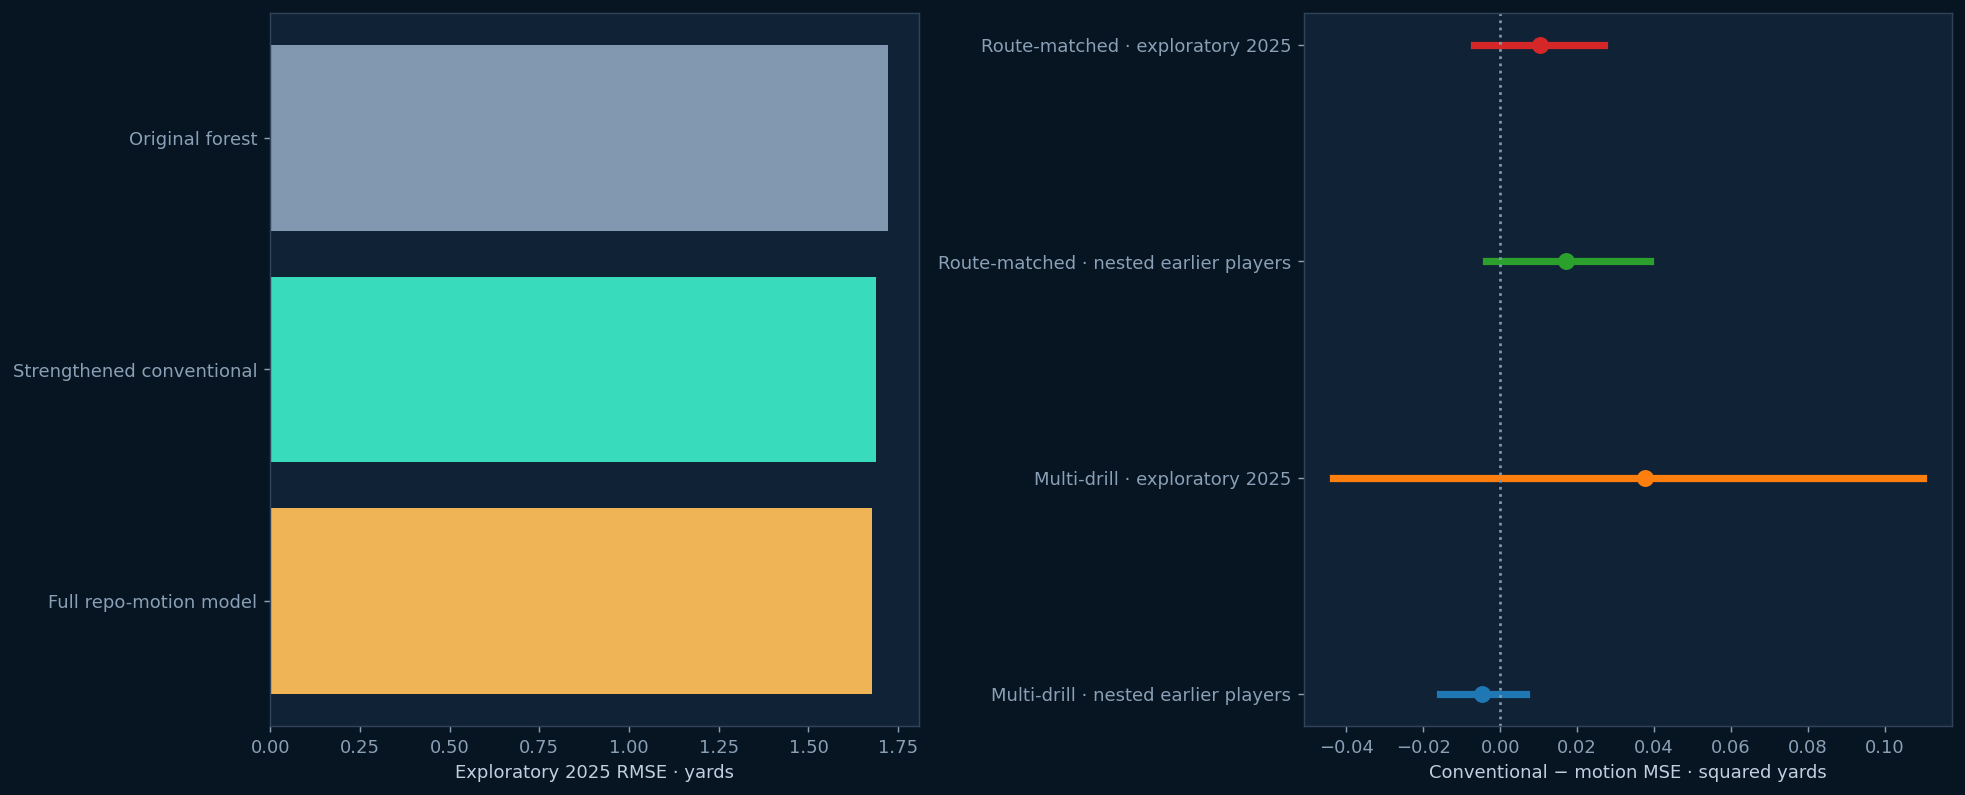

In [14]:
if READY:
    fig,ax=plt.subplots(1,2,figsize=(15,6),layout='constrained')
    vals=[report['results'][4]['test_rmse_yards'],repo_cohort['selected']['baseline']['test_rmse_yards'],repo_cohort['selected']['all']['test_rmse_yards']]
    ax[0].barh(['Original forest','Strengthened conventional','Full repo-motion model'],vals,color=['#8298b0','#39dbbd','#efb455']);ax[0].invert_yaxis();ax[0].set_xlabel('Exploratory 2025 RMSE · yards')
    intervals=[repo_nested['paired_improvement'],repo_cohort['selected']['all']['paired_vs_strong_conventional'],matched_trial['nested_earlier_data']['paired_improvement'],matched_trial['paired_improvement']]
    labels=['Multi-drill · nested earlier players','Multi-drill · exploratory 2025','Route-matched · nested earlier players','Route-matched · exploratory 2025']
    for i,v in enumerate(intervals):ax[1].plot(v['ci95'],[i,i],lw=4);ax[1].scatter(v['delta_mse'],i,s=70)
    ax[1].set_yticks(range(4),labels);ax[1].axvline(0,ls=':',color='#8298b0');ax[1].set_xlabel('Conventional − motion MSE · squared yards');plt.show()


## Receiver contribution after context adjustment
The next exploratory model expands each turn to three seconds: approach speed, retention, recovery, braking and propulsion integrals, heading change, bending energy, normalized area, and four Legendre speed modes. Route-specific drill medians supply twelve movement measures; weight and man-coverage interactions are predefined. Across 384 accepted attempts, 25.4% of study routes lack a matching usable motion record and retain imputation indicators.

A fixed context-only ExtraTrees model predicts separation from situation and coverage. Three player-group folds generate training residuals without fitting on the receiver whose residual is measured. Receiver/route/coverage residual means then train a regularized correction using conventional prospect measures, optionally adding mechanics. Equal total prospect weight and shrinkage limit sparse-group influence. These residuals are context-adjusted associations, not causal receiver effects. Each family selects among the same three ridge penalties inside four outer/three inner player folds on 2023–2024. The 2025 class never selects settings.

The first nested split yields conventional MSE 3.17585 and mechanics MSE 3.17059; the tiny increment is 0.00526 squared yards. Context alone is better at 3.16602. In exploratory 2025 the mechanics increment is effectively zero, 0.000055 with interval [−0.002047,0.001911]. Neither predefined man-coverage subset improves. Repeating the entire nested selection across three player partitions checks split dependence; shared players make these dependent diagnostics, not independent replications. Missing outcomes and unmeasured quarterback/defender effects remain unresolved. Figures 7 and 8 explain the longer movement window and this comparison.

Mechanism outer 0 {'context': 3.063931, 'physical': 3.06419, 'motion': 3.062083}
Mechanism outer 1 {'context': 3.37882, 'physical': 3.384405, 'motion': 3.38524}
Mechanism outer 2 {'context': 3.090382, 'physical': 3.094287, 'motion': 3.094869}
Mechanism outer 3 {'context': 3.124078, 'physical': 3.153107, 'motion': 3.133297}
{
  "status": "completed_actual_data_exploratory",
  "population": {
    "players_by_class": {
      "2023": 24,
      "2024": 19,
      "2025": 16
    },
    "routes_by_class": {
      "2023": 2829,
      "2024": 1989,
      "2025": 1424
    },
    "accepted_attempts": 384,
    "rejected_attempts": {
      "no qualifying turn": 51,
      "insufficient three-second turn window": 128,
      "insufficient approach speed": 1
    },
    "missing_movement_fraction": 0.25408522909323933,
    "missing_separation_by_class_coverage": {
      "(2023, 'MAN_COVERAGE')": 0.11534154535274356,
      "(2023, 'ZONE_COVERAGE')": 0.1138865368331922,
      "(2024, 'MAN_COVERAGE')": 0.13

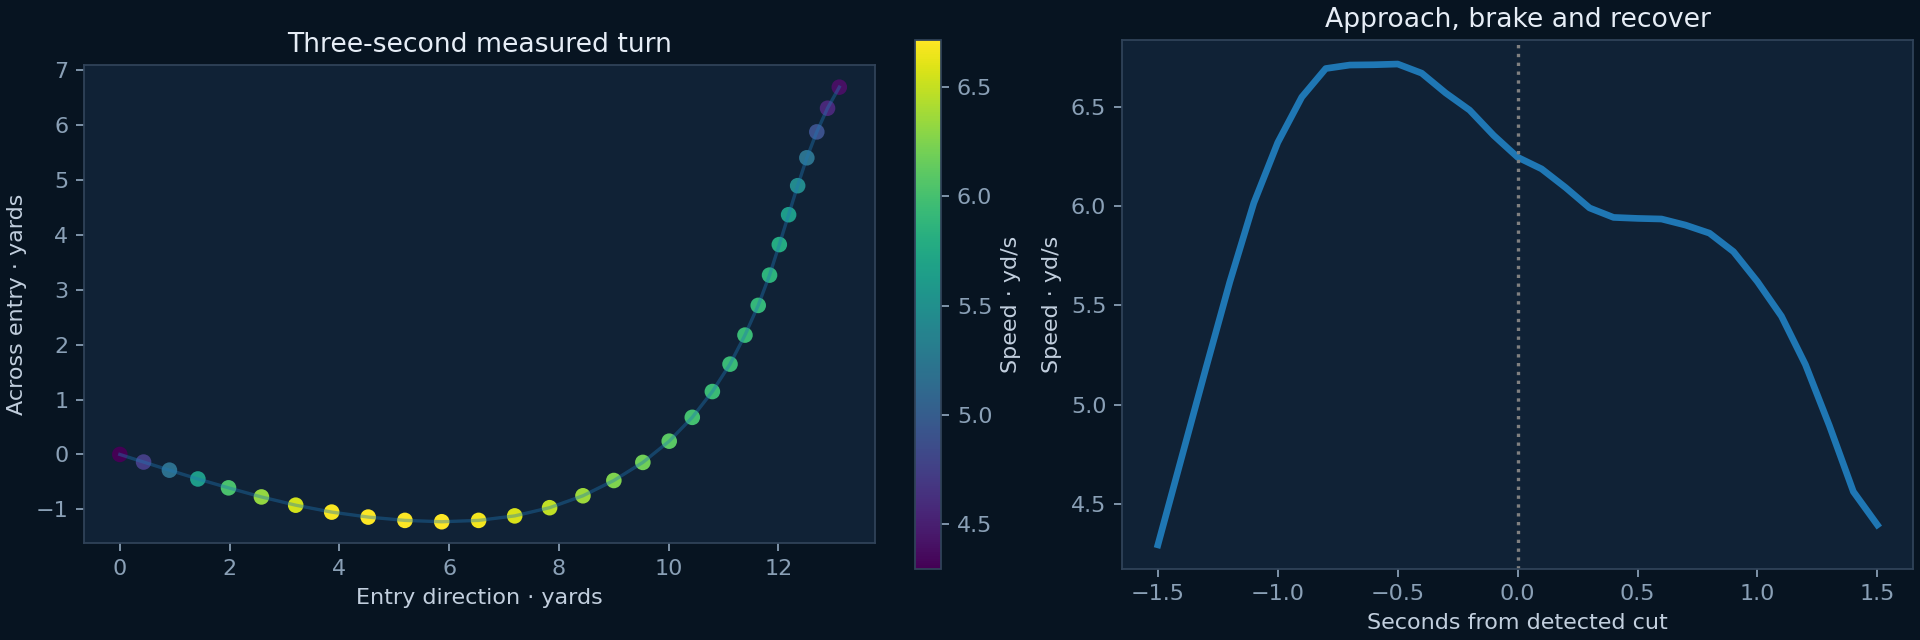

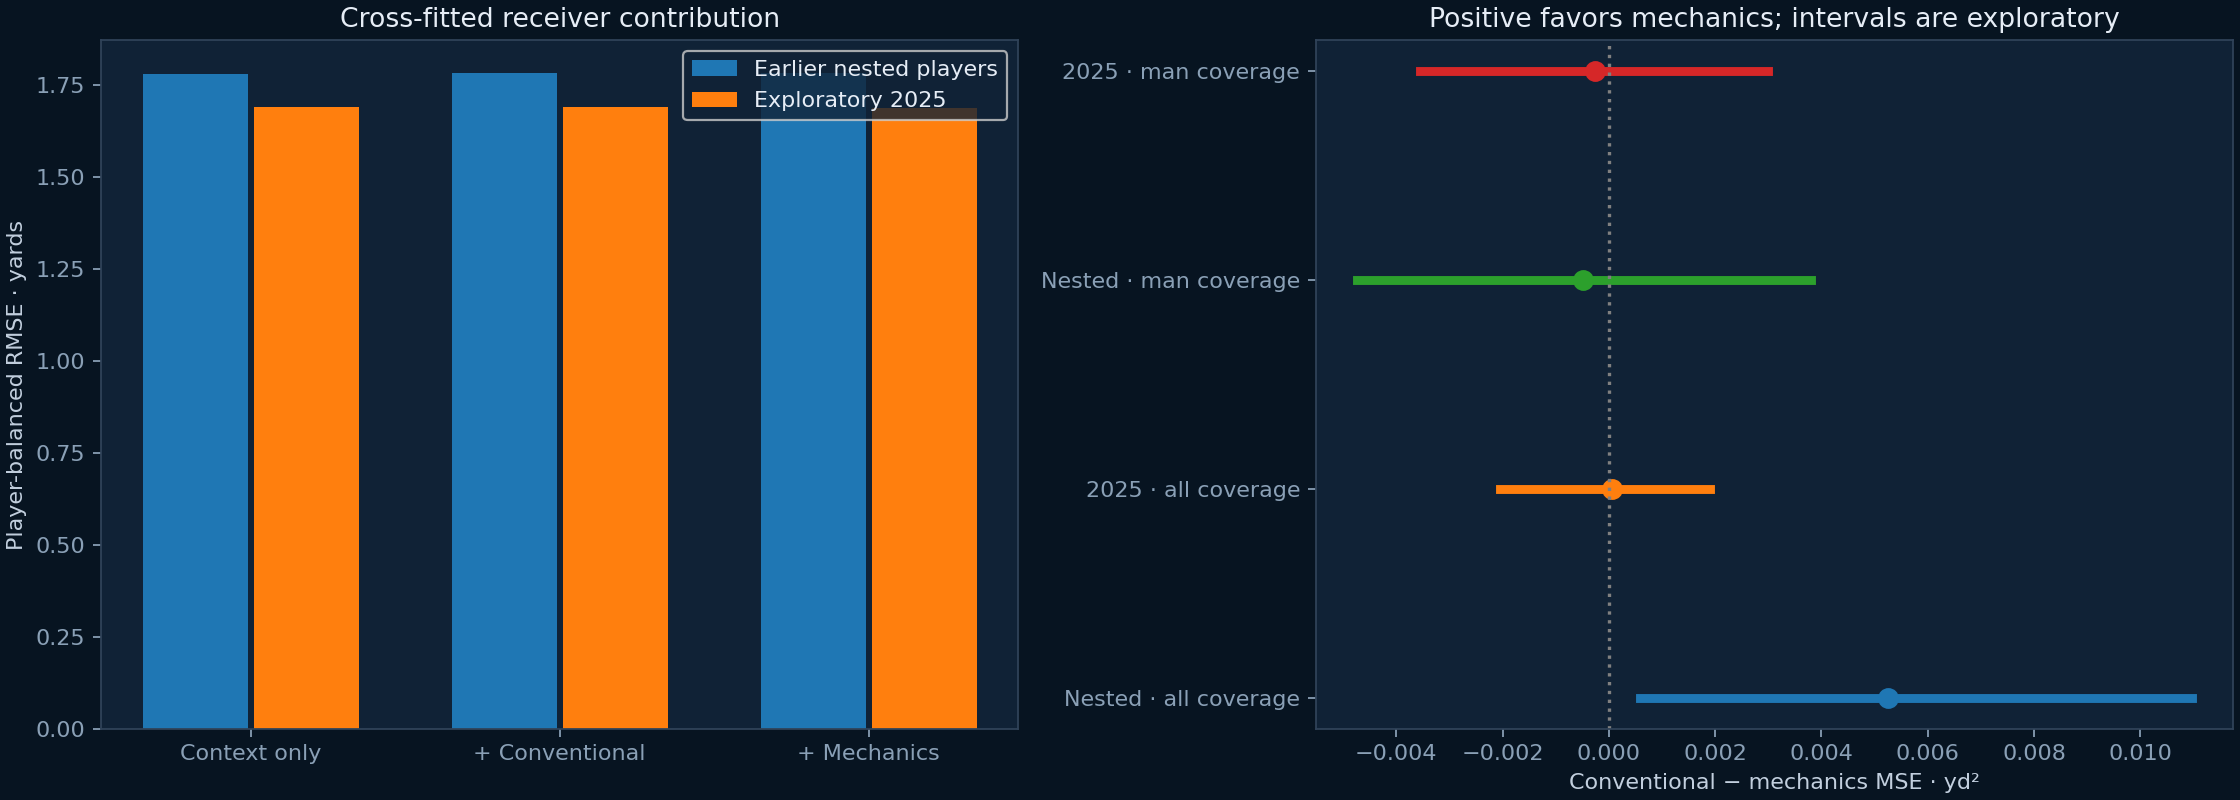

In [15]:
if READY:
    import mechanism as MF
    MECH_OUT=OUT.parent/'private_mechanism'
    mechanism_trial=MF.run(DATA_ROOT,MECH_OUT)
    split_stability=MF.split_stability(DATA_ROOT,MECH_OUT)
    print(json.dumps(split_stability,indent=2))
    display(Image(filename=str(MECH_OUT/'mechanism_geometry.png')))
    display(Image(filename=str(MECH_OUT/'mechanism_results.png')))


The explicit player-randomized checks give negative motion increments in all three partitions: −0.000261, −0.000011 and −0.001775 squared yards. Averaging each player across splits gives −0.000683, with conditional interval [−0.002485,0.001124]. The initial small positive result is therefore partition-dependent. The context-only model beats both corrections in every randomized partition. Twenty software tests pass; these tests verify code behavior, not a scouting advantage.

## Football implication and limits
The tested movement representations should not be marketed as established scouting improvements. The longer-window, context-adjusted model also fails to establish a transported advantage. Better cut annotations, opponent/missingness controls and independent future cohorts remain necessary. This study supports specific negative or uncertain results, not a universal conclusion about Combine tracking. Do not redistribute raw CSVs or private predictions.